# FreshSight
### Implementasi Computer Vision dan Deep Learning untuk Analisis dan Klasifikasi Kesegaran Buah Berdasarkan Citra Digital

Notebook tunggal ini memuat seluruh pipeline:

| Bagian | Isi | Status |
|---|---|---|
| 0 | Setup & konfigurasi | selesai |
| 1 | Dataset & EDA (termasuk deteksi leakage) | selesai |
| 2 | Praproses & pipeline `tf.data` | selesai |
| 3 | CNN baseline (dilatih dari nol) | selesai |
| 4 | MobileNetV3 (transfer learning) | selesai |
| 5 | Evaluasi & perbandingan model | selesai |
| 6 | Explainability: Grad-CAM + analisis defek | selesai |
| 7 | Inferensi `predict_and_explain()` | selesai |
| 8 | Uji generalisasi eksternal & auto-crop | selesai |
| 9 | Eksperimen data eksternal (AFQC + banana overripe) | selesai |

> **Status output: latihan penuh di GPU (RTX 3050).** CNN **25/25 epoch**; MobileNetV3 **10 epoch stage 1 + 6/10 epoch stage 2** (berhenti lebih awal karena EarlyStopping). Semua angka berasal dari eksekusi nyata. Jika dijalankan ulang di Colab GPU, angka bisa sedikit berbeda karena nondeterminisme GPU.

**Dataset:** 3 buah (apel, pisang, jeruk) × 2 kelas kesegaran (`fresh`, `rotten`).
Label `normal` digabung ke `fresh` → **6 kelas**.

**Menjalankan di Colab:** mount Google Drive, lalu set `DATASET_DIR` ke folder dataset
(atau letakkan di `/content/drive/MyDrive/dataset`). Di lokal, notebook mencari
`./dataset`, `../dataset`, atau `../materials/dataset`.

**Catatan metodologis:** split dilakukan per **klaster near-duplicate**, bukan per gambar,
karena dataset berisi banyak frame berurutan dari sesi yang sama.

## 0. Setup & konfigurasi

Semua path, seed, dan hyperparameter dasar didefinisikan di satu tempat.

In [1]:
%matplotlib inline
import collections
import hashlib
import json
import os
import random
import time
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from keras import layers
from PIL import Image, ImageDraw
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
PAD = 0.05          # padding konteks di sekitar bounding box
REBUILD = False     # True = timpa crop yang sudah ada

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})


def find_root():
    cwd = Path.cwd()
    if (cwd / "reports").exists() or (cwd / "materials").exists():
        return cwd
    if (cwd.parent / "reports").exists() or (cwd.parent / "materials").exists():
        return cwd.parent
    return cwd


def find_dataset_dir(root):
    candidates = []
    env = os.environ.get("DATASET_DIR")
    if env:
        candidates.append(Path(env))
    candidates += [
        root / "dataset",
        root.parent / "dataset",
        root / "materials" / "dataset",
        Path("/content/drive/MyDrive/dataset"),
    ]
    for c in candidates:
        if (c / "JPEGImages").is_dir() and (c / "Annotations").is_dir():
            return c.resolve()
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Set DATASET_DIR atau letakkan folder dataset "
        "berisi JPEGImages/ dan Annotations/."
    )


ROOT = find_root()
DATASET_DIR = find_dataset_dir(ROOT)
IMG_DIR = DATASET_DIR / "JPEGImages"
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
CROPS_DIR = ROOT / "data" / "crops"
MODEL_DIR = ROOT / "models"
for d in (REPORT_DIR, FIG_DIR, CROPS_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("ROOT       :", ROOT)
print("DATASET_DIR:", DATASET_DIR)
print("REPORT_DIR :", REPORT_DIR)
print("TF         :", tf.__version__, "| Keras:", keras.__version__)

2026-10-26 16:03:46.644634: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-26 16:03:46.786029: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


ROOT       : /workspace
DATASET_DIR: /workspace/materials/dataset
REPORT_DIR : /workspace/reports
TF         : 2.16.1 | Keras: 3.0.5


## 1. Dataset & Exploratory Data Analysis

Tujuan: mengenali struktur dataset, memeriksa kualitas data, dan menemukan potensi
*data leakage* **sebelum** model dibuat. Semua keputusan praproses bergantung pada hasil bagian ini.

### 1.1 Struktur folder

In [2]:
rows = []
for d in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    files = [f for f in d.rglob("*") if f.is_file()]
    exts = collections.Counter(f.suffix.lower() for f in files)
    total_mb = sum(f.stat().st_size for f in files) / (1024 * 1024)
    rows.append({
        "folder": d.name,
        "jumlah_file": len(files),
        "ekstensi": ", ".join(f"{k or '(tanpa ekstensi)'}: {v}" for k, v in exts.most_common()),
        "ukuran_MB": round(total_mb, 1),
    })

display(pd.DataFrame(rows))

semua_file = [f for f in DATASET_DIR.rglob("*") if f.is_file()]
print(f"Total file  : {len(semua_file)}")
print(f"Total ukuran: {sum(f.stat().st_size for f in semua_file) / (1024**2):.1f} MB")
print("Subfolder   :", sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir()))

,folder,jumlah_file,ekstensi,ukuran_MB
0,Annotations,3202,.xml: 3202,2.6
1,JPEGImages,3202,.jpg: 3202,166.2


Total file  : 6407


Total ukuran: 168.8 MB
Subfolder   : ['Annotations', 'JPEGImages']


### 1.2 Deteksi tipe struktur

In [3]:
subdirs = {p.name.lower() for p in DATASET_DIR.iterdir() if p.is_dir()}
has_voc = {"jpegimages", "annotations"} <= subdirs
has_train_split = bool({"train", "val", "valid", "validation", "test"} & subdirs)
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_like_dirs = [
    p for p in DATASET_DIR.iterdir()
    if p.is_dir() and any(f.suffix.lower() in image_exts for f in p.iterdir() if f.is_file())
]

if has_voc:
    tipe = "Pascal VOC (object detection): JPEGImages/ + Annotations/*.xml"
elif has_train_split:
    tipe = "Kasus A - sudah ada split train/val/test"
elif class_like_dirs:
    tipe = "Kasus B/C - folder per kelas"
else:
    tipe = "TIDAK DIKENALI"

print("Tipe struktur:", tipe)
print("Folder split train/val/test:", has_train_split)
print()
print(
    "Struktur ini BUKAN Kasus A/B/C: label kesegaran ada di anotasi XML per objek, "
    "bukan di nama folder. Unit data yang benar adalah CROP PER OBJEK (bounding box)."
)

Tipe struktur: Pascal VOC (object detection): JPEGImages/ + Annotations/*.xml
Folder split train/val/test: False

Struktur ini BUKAN Kasus A/B/C: label kesegaran ada di anotasi XML per objek, bukan di nama folder. Unit data yang benar adalah CROP PER OBJEK (bounding box).


### 1.3 Parsing anotasi XML → tabel objek

In [4]:
def parse_voc(ann_dir):
    records = []
    for xp in sorted(ann_dir.glob("*.xml")):
        try:
            root = ET.parse(xp).getroot()
        except ET.ParseError as e:
            records.append({"xml": xp.name, "error": str(e)})
            continue
        filename = (root.findtext("filename") or "").strip()
        size = root.find("size")
        width = int(size.findtext("width")) if size is not None and size.findtext("width") else None
        height = int(size.findtext("height")) if size is not None and size.findtext("height") else None
        for obj in root.findall("object"):
            name = (obj.findtext("name") or "").strip()
            bb = obj.find("bndbox")
            if not name or bb is None:
                continue
            records.append({
                "xml": xp.name,
                "filename": filename,
                "label": name,
                "x1": int(float(bb.findtext("xmin"))),
                "y1": int(float(bb.findtext("ymin"))),
                "x2": int(float(bb.findtext("xmax"))),
                "y2": int(float(bb.findtext("ymax"))),
                "width": width,
                "height": height,
            })
    return pd.DataFrame(records)


df = parse_voc(DATASET_DIR / "Annotations")
df["fruit"] = df["label"].str.split("_").str[-1]
df["state"] = df["label"].str.split("_").str[0]

STATE_ORDER = ["fresh", "normal", "rotten"]
FRUIT_ORDER = ["apple", "banana", "orange"]
LABEL_ORDER = [f"{s}_{f}" for f in FRUIT_ORDER for s in STATE_ORDER]

print("Jumlah objek :", len(df))
print("Label unik   :", sorted(df["label"].unique()))
print("Buah unik    :", sorted(df["fruit"].unique()))
print("State unik   :", sorted(df["state"].unique()))

tidak_valid = df[(df.x2 <= df.x1) | (df.y2 <= df.y1)]
tidak_dikenal = df[~df["state"].isin(STATE_ORDER) | ~df["fruit"].isin(FRUIT_ORDER)]
hilang = sorted(set(df.filename) - {p.name for p in (DATASET_DIR / "JPEGImages").iterdir()})

print(f"BBox tidak valid       : {len(tidak_valid)}")
print(f"Label di luar 3x3      : {len(tidak_dikenal)}")
print(f"Gambar tidak ditemukan : {len(hilang)}")
display(df.head())

Jumlah objek : 7087
Label unik   : ['fresh_apple', 'fresh_banana', 'fresh_orange', 'normal_apple', 'normal_banana', 'normal_orange', 'rotten_apple', 'rotten_banana', 'rotten_orange']
Buah unik    : ['apple', 'banana', 'orange']
State unik   : ['fresh', 'normal', 'rotten']
BBox tidak valid       : 0
Label di luar 3x3      : 0
Gambar tidak ditemukan : 0


,xml,filename,label,x1,y1,x2,y2,width,height,fruit,state
0,1.xml,1.jpg,fresh_apple,25,18,449,426,472,462,apple,fresh
1,10.xml,10.jpg,fresh_apple,37,30,407,402,448,426,apple,fresh
2,100.xml,100.jpg,rotten_orange,30,32,410,422,442,422,orange,rotten
3,1000.xml,1000.jpg,normal_orange,189,231,347,383,640,480,orange,normal
4,1001.xml,1001.jpg,normal_orange,191,229,348,385,640,480,orange,normal


### 1.4 Distribusi kelas

,label,jumlah_objek,persen
0,fresh_apple,705,9.9
1,normal_apple,1103,15.6
2,rotten_apple,179,2.5
3,fresh_banana,904,12.8
4,normal_banana,1356,19.1
5,rotten_banana,781,11.0
6,fresh_orange,737,10.4
7,normal_orange,995,14.0
8,rotten_orange,327,4.6


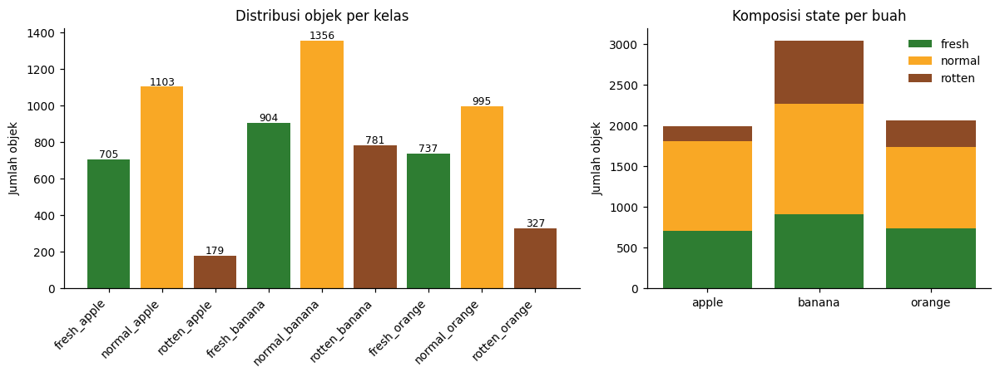

Rasio kelas: 7.6x (normal_banana=1356 vs rotten_apple=179)


In [5]:
label_counts = df["label"].value_counts().reindex(LABEL_ORDER).fillna(0).astype(int)
COLORS = {"fresh": "#2e7d32", "normal": "#f9a825", "rotten": "#8d4b26"}

display(pd.DataFrame({
    "label": LABEL_ORDER,
    "jumlah_objek": label_counts.values,
    "persen": (label_counts.values / len(df) * 100).round(1),
}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
warna = [COLORS[s] for s in [l.split("_")[0] for l in LABEL_ORDER]]
axes[0].bar(range(len(LABEL_ORDER)), label_counts.values, color=warna)
axes[0].set_xticks(range(len(LABEL_ORDER)))
axes[0].set_xticklabels(LABEL_ORDER, rotation=45, ha="right")
axes[0].set_ylabel("Jumlah objek")
axes[0].set_title("Distribusi objek per kelas")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 10, str(v), ha="center", fontsize=8)

pivot = df.pivot_table(index="fruit", columns="state", values="label", aggfunc="count").reindex(
    index=FRUIT_ORDER, columns=STATE_ORDER).fillna(0)
bottom = np.zeros(len(pivot))
for s in STATE_ORDER:
    axes[1].bar(pivot.index, pivot[s], bottom=bottom, label=s, color=COLORS[s])
    bottom += pivot[s].values
axes[1].set_title("Komposisi state per buah")
axes[1].set_ylabel("Jumlah objek")
axes[1].legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribusi_kelas.png", bbox_inches="tight")
plt.show()

rasio = label_counts.max() / max(label_counts.min(), 1)
print(f"Rasio kelas: {rasio:.1f}x ({label_counts.idxmax()}={label_counts.max()} vs "
      f"{label_counts.idxmin()}={label_counts.min()})")

### 1.5 Contoh gambar per kelas

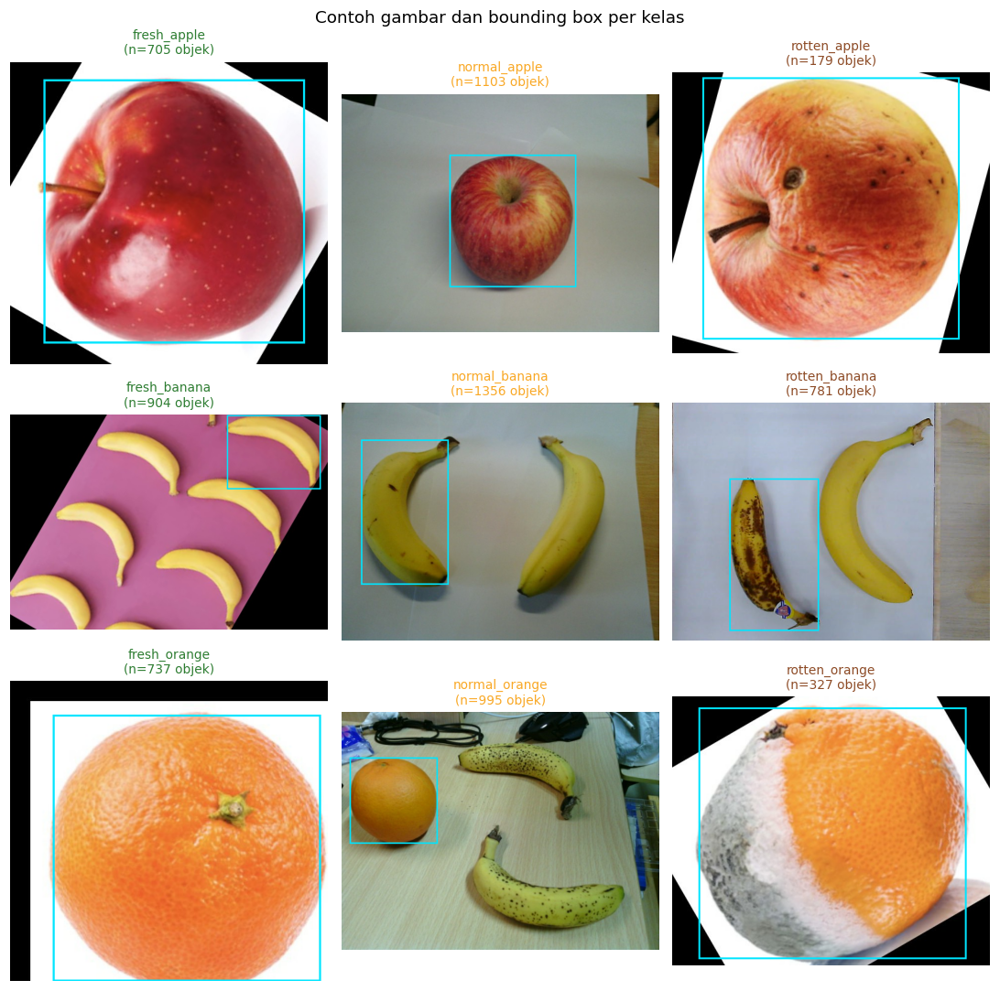

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, fruit in zip(axes, FRUIT_ORDER):
    for ax2, state in zip(ax, STATE_ORDER):
        label = f"{state}_{fruit}"
        subset = df[df.label == label]
        row = subset.sample(1, random_state=SEED).iloc[0]
        img = Image.open(IMG_DIR / row.filename).convert("RGB")
        draw = ImageDraw.Draw(img)
        if row.width and row.height:
            sx, sy = img.width / row.width, img.height / row.height
        else:
            sx = sy = 1.0
        draw.rectangle([row.x1 * sx, row.y1 * sy, row.x2 * sx, row.y2 * sy],
                       outline="#00e5ff", width=3)
        ax2.imshow(img)
        ax2.set_title(f"{label}\n(n={len(subset)} objek)", color=COLORS[state], fontsize=9)
        ax2.axis("off")

fig.suptitle("Contoh gambar dan bounding box per kelas", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_contoh_per_kelas.png", bbox_inches="tight")
plt.show()

### 1.6 Ukuran gambar, file korup, dan dHash

Jumlah gambar: 3202 | korup: 0


,width_px,height_px
count,3202.0,3202.0
mean,592.0,469.5
std,106.4,65.9
min,416.0,416.0
25%,494.0,442.0
50%,640.0,480.0
75%,640.0,480.0
max,2104.0,2000.0


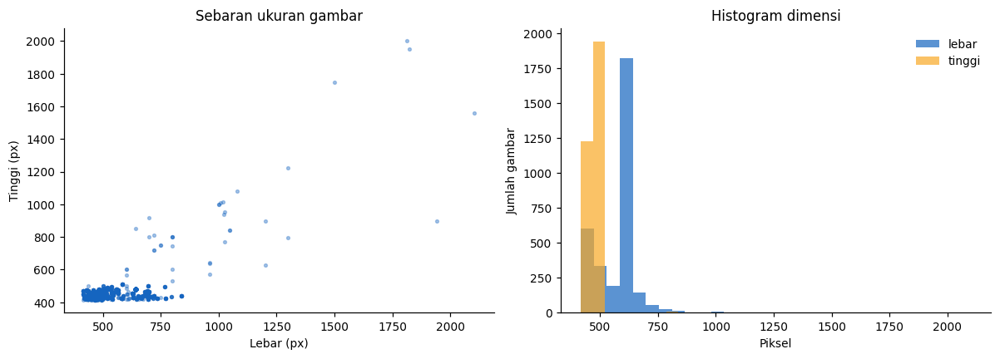

Ketidakcocokan ukuran XML vs gambar: 0


In [7]:
def dhash(im, size=8):
    """dHash 64-bit untuk mendeteksi gambar hampir kembar."""
    small = im.convert("L").resize((size + 1, size), Image.LANCZOS)
    arr = np.asarray(small, dtype=np.int16)
    bits = (arr[:, 1:] > arr[:, :-1]).reshape(-1)
    return int.from_bytes(np.packbits(bits).tobytes(), "big")


img_rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.suffix.lower() not in image_exts:
        continue
    entry = {"filename": p.name, "bytes": p.stat().st_size}
    try:
        with Image.open(p) as im:
            entry["width_px"], entry["height_px"] = im.size
            entry["mode"] = im.mode
            entry["dhash"] = dhash(im)
        with Image.open(p) as im:
            im.verify()
        entry["corrupt"] = False
        entry["md5"] = hashlib.md5(p.read_bytes()).hexdigest()
    except Exception as e:
        entry.update({"width_px": None, "height_px": None, "mode": None,
                      "dhash": 0, "corrupt": True, "md5": None, "error": str(e)})
    img_rows.append(entry)

img_df = pd.DataFrame(img_rows)
print("Jumlah gambar:", len(img_df), "| korup:", int(img_df["corrupt"].sum()))

ok = img_df[~img_df["corrupt"]]
display(ok[["width_px", "height_px"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(ok.width_px, ok.height_px, s=6, alpha=0.35, color="#1565c0")
axes[0].set_xlabel("Lebar (px)"); axes[0].set_ylabel("Tinggi (px)")
axes[0].set_title("Sebaran ukuran gambar")
axes[1].hist(ok.width_px, bins=30, alpha=0.7, label="lebar", color="#1565c0")
axes[1].hist(ok.height_px, bins=30, alpha=0.7, label="tinggi", color="#f9a825")
axes[1].set_xlabel("Piksel"); axes[1].set_ylabel("Jumlah gambar")
axes[1].set_title("Histogram dimensi"); axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_ukuran_gambar.png", bbox_inches="tight")
plt.show()

cek = df.drop_duplicates("filename")[["filename", "width", "height"]].merge(
    ok[["filename", "width_px", "height_px"]], on="filename", how="left")
mismatch = cek[(cek.width != cek.width_px) | (cek.height != cek.height_px)]
print("Ketidakcocokan ukuran XML vs gambar:", len(mismatch))

### 1.7 Duplikat persis (MD5)

Grup duplikat persis : 109
Gambar duplikat ekstra: 109


,md5,filename
3089,ffe6a0deab4b83e24bbb805d2164ce66,"[1593.jpg, 307.jpg]"
32,02ea77c716c170ceaaec5908b404d676,"[237.jpg, 705.jpg]"
52,0450363d0a794f48af471d891b0610a9,"[1667.jpg, 39.jpg]"
62,0562b73004bc7080f2984f70bbcbde46,"[1660.jpg, 26.jpg]"
125,0af141e0688240d4187c4b53d8c9ea85,"[376.jpg, 589.jpg]"
2695,e03203426afd4b1b40d9de486ac5056e,"[1679.jpg, 63.jpg]"
2735,e3fa1b250493340599d63b8f95511190,"[640.jpg, 707.jpg]"
2757,e59369ed2ca0edea605f3f4c484e502d,"[559.jpg, 631.jpg]"
2768,e6a3e301614efa5a47629bb4b8b39398,"[1592.jpg, 306.jpg]"
2799,e9208af761e1619e8d29027279418e03,"[1674.jpg, 52.jpg]"


Duplikat dengan label berbeda: 5
   [('628.jpg', ('rotten_apple',)), ('773.jpg', ('fresh_apple',))]
   [('1662.jpg', ('normal_apple',)), ('29.jpg', ('fresh_apple',))]
   [('1580.jpg', ('normal_apple',)), ('294.jpg', ('fresh_apple',))]
   [('503.jpg', ('fresh_orange',)), ('703.jpg', ('normal_orange',))]
   [('1582.jpg', ('normal_apple',)), ('296.jpg', ('fresh_apple',))]


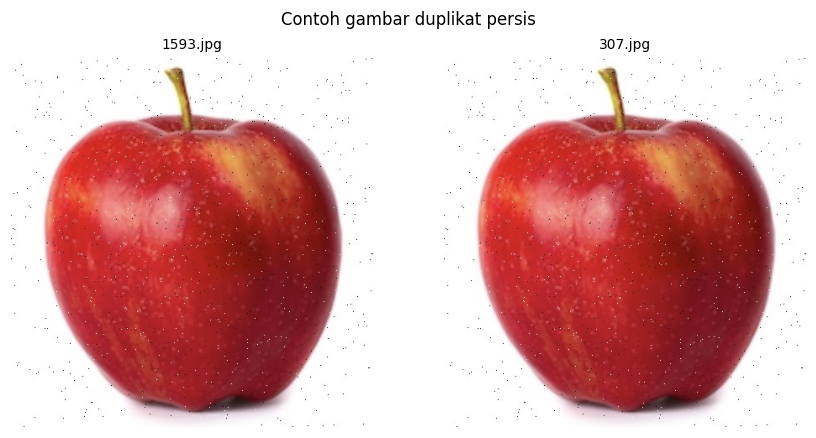

In [8]:
dup_groups = (ok.dropna(subset=["md5"]).groupby("md5")["filename"].agg(list).reset_index())
dup_groups = dup_groups[dup_groups["filename"].str.len() > 1].sort_values(
    by="filename", key=lambda s: s.str.len(), ascending=False)
print(f"Grup duplikat persis : {len(dup_groups)}")
print(f"Gambar duplikat ekstra: {sum(len(v) - 1 for v in dup_groups['filename'])}")
display(dup_groups.head(10))

label_map = df.groupby("filename")["label"].agg(lambda s: sorted(set(s)))
konflik = []
for files in dup_groups["filename"]:
    sets = [tuple(label_map.get(f, [])) for f in files]
    if len(set(sets)) > 1:
        konflik.append(list(zip(files, sets)))
print("Duplikat dengan label berbeda:", len(konflik))
for item in konflik[:5]:
    print("  ", item)

if len(dup_groups):
    contoh = dup_groups.iloc[0]["filename"][:2]
    fig, axes = plt.subplots(1, len(contoh), figsize=(4 * len(contoh), 4))
    for ax, f in zip(np.atleast_1d(axes), contoh):
        ax.imshow(Image.open(IMG_DIR / f).convert("RGB"))
        ax.set_title(f, fontsize=9); ax.axis("off")
    fig.suptitle("Contoh gambar duplikat persis")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_contoh_duplikat.png", bbox_inches="tight")
    plt.show()

### 1.8 Near-duplicate & strategi split

Dataset ini berisi banyak frame berurutan dari sesi yang sama. Split acak per gambar masih
membocorkan klaster tersebut ke test. Karena itu gambar dikelompokkan dengan **dHash ≤ 2**
(dan ukuran mirip), lalu split dilakukan **per klaster**.

Gambar dengan >1 label berbeda: 1308 dari 3202 gambar
Objek sebelum dedupe: 7087 | sesudah: 6977 (hilang 110)
Gambar unik untuk clustering: 3093
Klaster near-duplicate (dHash<=2): 1379
  klaster >1 gambar : 640
  gambar di dalamnya: 2354 (76.1%)
  klaster terbesar  : 43 gambar


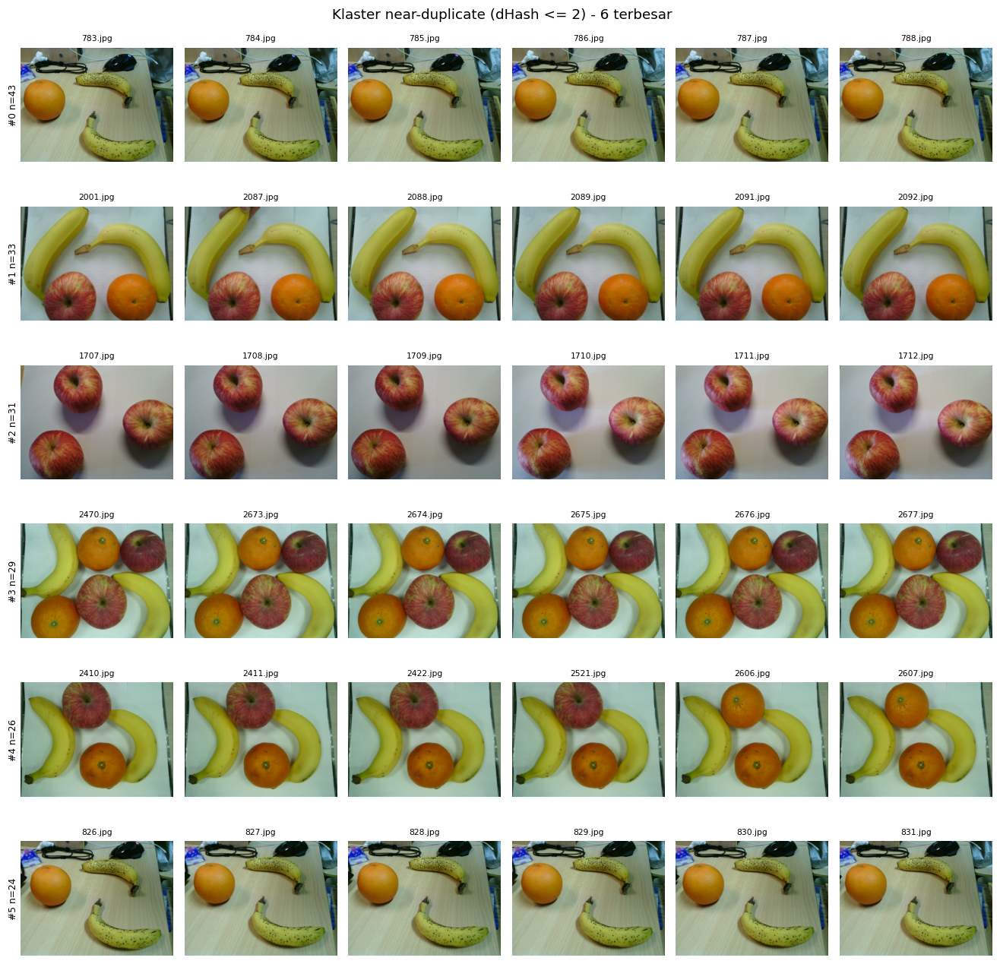

,strategi,klaster bocor
0,naif per objek,546
1,acak per gambar,379
2,per klaster (dipakai),0


Gambar sumber bocor antar split: 0
Objek per split: {'train': 4871, 'val': 1109, 'test': 997}


In [9]:
per_image_labels = df.groupby("filename")["label"].agg(lambda s: sorted(set(s)))
campuran = per_image_labels[per_image_labels.str.len() > 1]
print(f"Gambar dengan >1 label berbeda: {len(campuran)} dari {df.filename.nunique()} gambar")

# --- dedupe persis ---
hash_to_keep = ok.dropna(subset=["md5"]).drop_duplicates("md5").set_index("md5")["filename"].to_dict()
img_df["is_duplicate"] = img_df.apply(
    lambda r: bool(r["md5"]) and hash_to_keep.get(r["md5"], r["filename"]) != r["filename"], axis=1)
df_dedup = df[df.filename.isin(set(hash_to_keep.values()))].copy()
ok_unique = ok[ok.filename.isin(df_dedup.filename.unique())].reset_index(drop=True)
print(f"Objek sebelum dedupe: {len(df)} | sesudah: {len(df_dedup)} "
      f"(hilang {len(df) - len(df_dedup)})")
print(f"Gambar unik untuk clustering: {len(ok_unique)}")


def popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)


DHASH_THR = 2
SIZE_TOL = 0.10
hashes = ok_unique["dhash"].to_numpy(dtype=np.uint64)
names_u = ok_unique["filename"].to_numpy()
wh = ok_unique[["width_px", "height_px"]].to_numpy(dtype=float)
parent = list(range(len(hashes)))


def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra


for i in range(len(hashes) - 1):
    d = popcount64(hashes[i + 1:] ^ hashes[i])
    for off in np.where(d <= DHASH_THR)[0]:
        j = i + 1 + int(off)
        if (abs(wh[i, 0] - wh[j, 0]) / max(wh[i, 0], wh[j, 0]) <= SIZE_TOL and
                abs(wh[i, 1] - wh[j, 1]) / max(wh[i, 1], wh[j, 1]) <= SIZE_TOL):
            union(i, j)

cluster_of = {names_u[i]: find(i) for i in range(len(names_u))}
ok_unique["cluster"] = ok_unique["filename"].map(cluster_of)
cluster_sizes = ok_unique.groupby("cluster").size()
klaster_multi = cluster_sizes[cluster_sizes > 1]

print(f"Klaster near-duplicate (dHash<={DHASH_THR}): {len(cluster_sizes)}")
print(f"  klaster >1 gambar : {len(klaster_multi)}")
print(f"  gambar di dalamnya: {int(klaster_multi.sum())} "
      f"({klaster_multi.sum() / len(ok_unique) * 100:.1f}%)")
print(f"  klaster terbesar  : {int(cluster_sizes.max())} gambar")

top_clusters = cluster_sizes.sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(6, 6, figsize=(12, 12))
for r, cid in enumerate(top_clusters):
    files = ok_unique.loc[ok_unique.cluster == cid, "filename"].tolist()[:6]
    for c in range(6):
        ax = axes[r, c]; ax.axis("off")
        if c < len(files):
            ax.imshow(Image.open(IMG_DIR / files[c]).convert("RGB"))
            ax.set_title(files[c], fontsize=7)
    axes[r, 0].text(-0.08, 0.5, f"#{r} n={cluster_sizes[cid]}",
                    transform=axes[r, 0].transAxes, rotation=90, va="center", fontsize=8)
fig.suptitle(f"Klaster near-duplicate (dHash <= {DHASH_THR}) - 6 terbesar", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_klaster_duplikat.png", bbox_inches="tight")
plt.show()

# --- split per klaster, proporsional terhadap jumlah objek ---
df_dedup["cluster"] = df_dedup["filename"].map(cluster_of)
primary = df_dedup.groupby("cluster")["label"].agg(lambda s: s.value_counts().idxmax())
clusters_by_label = collections.defaultdict(list)
for cid, lab in primary.items():
    clusters_by_label[lab].append(cid)

split_by_cluster = {}
cluster_obj_sizes = df_dedup.groupby("cluster").size()
rng = np.random.RandomState(SEED)
for lab, cids in clusters_by_label.items():
    cids = sorted(cids)
    rng.shuffle(cids)
    total_lab = cluster_obj_sizes[cids].sum()
    cum = 0
    for cid in cids:
        frac = (cum + cluster_obj_sizes[cid] / 2) / total_lab
        split_by_cluster[cid] = "train" if frac < 0.70 else ("val" if frac < 0.85 else "test")
        cum += cluster_obj_sizes[cid]

df_dedup["split"] = df_dedup["cluster"].map(split_by_cluster)


def leak_count(frame, col):
    return int((frame.groupby("cluster")[col].nunique() > 1).sum())


naif = df_dedup.assign(split_naif=rng.choice(["train", "val", "test"], len(df_dedup), p=[.7, .15, .15]))
uniq_files = sorted(df_dedup.filename.unique())
rng.shuffle(uniq_files)
n = len(uniq_files)
n_tr, n_va = int(0.7 * n), int(0.15 * n)
split_file = {}
for f in uniq_files[:n_tr]:
    split_file[f] = "train"
for f in uniq_files[n_tr:n_tr + n_va]:
    split_file[f] = "val"
for f in uniq_files[n_tr + n_va:]:
    split_file[f] = "test"
per_gambar = df_dedup.assign(split_gambar=df_dedup.filename.map(split_file))

display(pd.DataFrame([
    {"strategi": "naif per objek", "klaster bocor": leak_count(naif, "split_naif")},
    {"strategi": "acak per gambar", "klaster bocor": leak_count(per_gambar, "split_gambar")},
    {"strategi": "per klaster (dipakai)", "klaster bocor": leak_count(df_dedup, "split")},
]))
print("Gambar sumber bocor antar split:",
      int((df_dedup.groupby("filename")["split"].nunique() > 1).sum()))
print("Objek per split:", df_dedup["split"].value_counts().to_dict())

### 1.9 Skema 6 kelas + class weight + manifest

In [10]:
df_dedup["label6"] = (
    df_dedup["state"].map(lambda s: "fresh" if s in ("fresh", "normal") else "rotten")
    + "_" + df_dedup["fruit"]
)
LABEL6 = [f"{s}_{f}" for f in FRUIT_ORDER for s in ("fresh", "rotten")]

tabel_split6 = pd.crosstab(df_dedup["label6"], df_dedup["split"]).reindex(LABEL6).fillna(0).astype(int)
print("Distribusi 6 kelas (normal -> fresh) per split:")
display(tabel_split6)


def class_weights(counts):
    counts = np.asarray(counts, dtype=float)
    return counts.sum() / (len(counts) * counts)


weights6 = class_weights(tabel_split6["train"].values)
tabel_bobot6 = pd.DataFrame({
    "label": LABEL6,
    "total_objek": tabel_split6.sum(axis=1).values,
    "train_objek": tabel_split6["train"].values,
    "class_weight": np.round(weights6, 3),
})
print("Class weight 6 kelas (dari train):")
display(tabel_bobot6)

tabel_bobot6.to_csv(REPORT_DIR / "01_class_weights_6kelas.csv", index=False)
tabel_split6.to_csv(REPORT_DIR / "01_distribusi_6kelas_per_split.csv")

manifest_cols = ["filename", "label", "label6", "fruit", "state",
                 "x1", "y1", "x2", "y2", "width", "height", "cluster", "split"]
df_dedup[manifest_cols].to_csv(REPORT_DIR / "01_split_manifest.csv", index=False)
print("Manifest:", REPORT_DIR / "01_split_manifest.csv", f"({len(df_dedup)} objek)")

CLASSES = LABEL6
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
CLASS_WEIGHT = {CLASS_TO_ID[r.label]: float(r.class_weight) for r in tabel_bobot6.itertuples()}
manifest = df_dedup.reset_index(drop=True).copy()

Distribusi 6 kelas (normal -> fresh) per split:


split,test,train,val
label6,,,
fresh_apple,230,1198,298
rotten_apple,27,124,27
fresh_banana,354,1571,323
rotten_banana,101,540,137
fresh_orange,239,1212,273
rotten_orange,46,226,51


Class weight 6 kelas (dari train):


,label,total_objek,train_objek,class_weight
0,fresh_apple,1726,1198,0.678
1,rotten_apple,178,124,6.547
2,fresh_banana,2248,1571,0.517
3,rotten_banana,778,540,1.503
4,fresh_orange,1724,1212,0.670
5,rotten_orange,323,226,3.592


Manifest: /workspace/reports/01_split_manifest.csv (6977 objek)


### 1.10 Ringkasan temuan

In [11]:
ringkasan = {
    "dataset_dir": str(DATASET_DIR),
    "tipe_struktur": tipe,
    "jumlah_gambar": int(len(img_df)),
    "jumlah_gambar_unik": int(img_df["md5"].nunique()),
    "jumlah_objek": int(len(df)),
    "jumlah_objek_setelah_dedupe": int(len(df_dedup)),
    "jumlah_file_korup": int(img_df["corrupt"].sum()),
    "jumlah_grup_duplikat": int(len(dup_groups)),
    "gambar_multilabel": int(len(campuran)),
    "distribusi_6kelas": {k: int(v) for k, v in tabel_split6.sum(axis=1).items()},
    "near_duplicate": {
        "ambang_dhash": DHASH_THR,
        "jumlah_klaster": int(len(cluster_sizes)),
        "klaster_multi": int(len(klaster_multi)),
        "gambar_dalam_klaster_multi": int(klaster_multi.sum()),
        "klaster_terbesar": int(cluster_sizes.max()),
    },
    "leakage": {
        "naif_per_objek": int(leak_count(naif, "split_naif")),
        "acak_per_gambar": int(leak_count(per_gambar, "split_gambar")),
        "per_klaster": int(leak_count(df_dedup, "split")),
    },
    "split": {k: int(v) for k, v in df_dedup["split"].value_counts().items()},
    "class_weight_6kelas": {l: round(float(w), 4) for l, w in zip(LABEL6, weights6)},
}
(REPORT_DIR / "01_dataset_summary.json").write_text(json.dumps(ringkasan, indent=2), encoding="utf-8")

print(f"Gambar     : {len(img_df)} ({len(dup_groups)} grup duplikat persis)")
print(f"Objek      : {len(df)} -> dedupe {len(df_dedup)}")
print(f"Near-dup   : {len(cluster_sizes)} klaster, {int(klaster_multi.sum())} gambar di klaster >1")
print(f"Leakage    : naif={leak_count(naif, 'split_naif')}, "
      f"per gambar={leak_count(per_gambar, 'split_gambar')}, per klaster=0")
print(f"Split      : {df_dedup['split'].value_counts().to_dict()}")
print(f"Kelas      : {CLASSES}")
print(f"Bobot      : { {k: round(v, 3) for k, v in CLASS_WEIGHT.items()} }")

Gambar     : 3202 (109 grup duplikat persis)
Objek      : 7087 -> dedupe 6977
Near-dup   : 1379 klaster, 2354 gambar di klaster >1
Leakage    : naif=546, per gambar=379, per klaster=0
Split      : {'train': 4871, 'val': 1109, 'test': 997}
Kelas      : ['fresh_apple', 'rotten_apple', 'fresh_banana', 'rotten_banana', 'fresh_orange', 'rotten_orange']
Bobot      : {0: 0.678, 1: 6.547, 2: 0.517, 3: 1.503, 4: 0.67, 5: 3.592}


## 2. Praproses & pipeline data

Setiap objek dipotong dari bounding box (+5% konteks), di-resize ke **224×224**, lalu disimpan
ke `data/crops/{split}/{label}/`. Crop disimpan di disk agar training cepat dan hemat RAM.

Augmentasi (flip, rotasi, zoom, brightness, contrast) **hanya** diterapkan pada train.
Val/test deterministik. Semua gambar dimuat sebagai `float32` di **[0, 1]**.

### 2.1 Distribusi 6 kelas per split

split,test,train,val
label6,,,
fresh_apple,230,1198,298
rotten_apple,27,124,27
fresh_banana,354,1571,323
rotten_banana,101,540,137
fresh_orange,239,1212,273
rotten_orange,46,226,51


Total: 6977 | per split: {'train': 4871, 'val': 1109, 'test': 997}


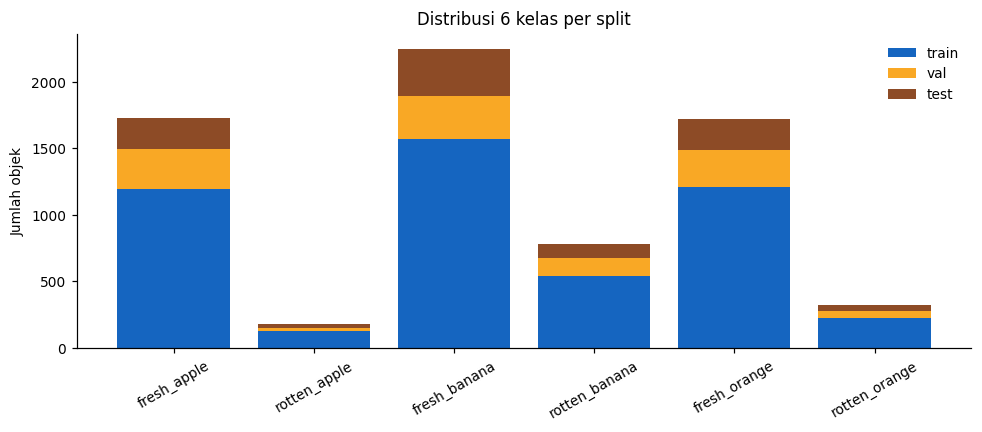

In [12]:
assert set(manifest["label6"]) == set(CLASSES)
tabel = pd.crosstab(manifest["label6"], manifest["split"]).reindex(CLASSES).fillna(0).astype(int)
display(tabel)
print("Total:", len(manifest), "| per split:", manifest["split"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(len(tabel))
colors = {"train": "#1565c0", "val": "#f9a825", "test": "#8d4b26"}
for s in ["train", "val", "test"]:
    ax.bar(tabel.index, tabel[s], bottom=bottom, label=s, color=colors[s])
    bottom += tabel[s].values
ax.set_ylabel("Jumlah objek"); ax.set_title("Distribusi 6 kelas per split")
ax.tick_params(axis="x", rotation=30); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_distribusi_6kelas.png", bbox_inches="tight")
plt.show()

### 2.2 Generate crop per objek

In [13]:
def crop_box(row, width, height, pad=PAD):
    bw, bh = row.x2 - row.x1, row.y2 - row.y1
    x1 = max(0, int(round(row.x1 - pad * bw)))
    y1 = max(0, int(round(row.y1 - pad * bh)))
    x2 = min(width, int(round(row.x2 + pad * bw)))
    y2 = min(height, int(round(row.y2 + pad * bh)))
    return x1, y1, x2, y2


records = manifest.reset_index(drop=True)
t0 = time.time()
gagal = []

for idx, row in tqdm(records.iterrows(), total=len(records), desc="Membuat crop"):
    out = CROPS_DIR / row["split"] / row["label6"] / f"{Path(row['filename']).stem}__{idx:05d}.jpg"
    if out.exists() and not REBUILD:
        continue
    try:
        with Image.open(IMG_DIR / row["filename"]) as im:
            im = im.convert("RGB")
            x1, y1, x2, y2 = crop_box(row, im.width, im.height)
            if x2 - x1 < 2 or y2 - y1 < 2:
                gagal.append((row["filename"], "bbox terlalu kecil")); continue
            crop = im.crop((x1, y1, x2, y2)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
        out.parent.mkdir(parents=True, exist_ok=True)
        crop.save(out, quality=92)
    except Exception as e:
        gagal.append((row["filename"], str(e)))

print(f"Selesai dalam {time.time() - t0:.1f} detik | gagal: {len(gagal)}")
if gagal:
    display(pd.DataFrame(gagal, columns=["filename", "error"]).head(10))

crop_manifest = records.copy()
crop_manifest["crop_path"] = [
    (CROPS_DIR / r["split"] / r["label6"] / f"{Path(r['filename']).stem}__{i:05d}.jpg")
    .relative_to(ROOT).as_posix()
    for i, r in records.iterrows()
]
crop_manifest["label_id"] = crop_manifest["label6"].map(CLASS_TO_ID)
crop_manifest.to_csv(REPORT_DIR / "02_crops_manifest.csv", index=False)
print("Manifest crop:", REPORT_DIR / "02_crops_manifest.csv", f"({len(crop_manifest)} baris)")

Membuat crop:   0%|          | 0/6977 [00:00<?, ?it/s]

Selesai dalam 23.5 detik | gagal: 0


Manifest crop: /workspace/reports/02_crops_manifest.csv (6977 baris)


### 2.3 Verifikasi crop & contoh hasil

Crop hilang: 0


Cek crop:   0%|          | 0/6977 [00:00<?, ?it/s]

Crop korup : 0
Ukuran unik: [(224, 224)]
Total crop : 6977
Per split  : {'train': 4871, 'val': 1109, 'test': 997}
Gambar sumber bocor antar split: 0
Klaster bocor antar split      : 0


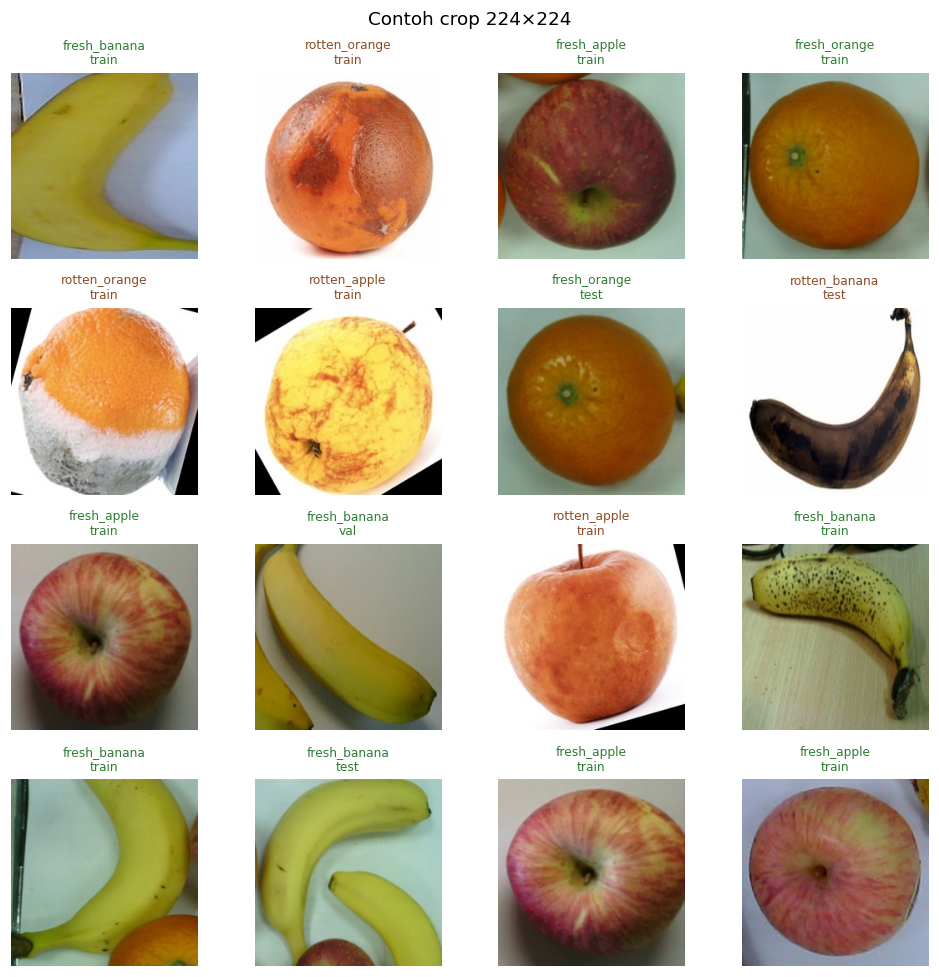

In [14]:
hilang = [p for p in crop_manifest["crop_path"] if not (ROOT / p).exists()]
print("Crop hilang:", len(hilang))

ukuran, korup = [], []
for p in tqdm(crop_manifest["crop_path"], desc="Cek crop"):
    try:
        with Image.open(ROOT / p) as im:
            ukuran.append(im.size)
    except Exception as e:
        korup.append((p, str(e)))

print("Crop korup :", len(korup))
print("Ukuran unik:", sorted(set(ukuran))[:5])
print("Total crop :", len(crop_manifest))
print("Per split  :", crop_manifest["split"].value_counts().to_dict())
print("Gambar sumber bocor antar split:", int((crop_manifest.groupby("filename")["split"].nunique() > 1).sum()))
print("Klaster bocor antar split      :", int((crop_manifest.groupby("cluster")["split"].nunique() > 1).sum()))

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
sampel = crop_manifest.sample(16, random_state=SEED)
for ax, (_, r) in zip(axes.ravel(), sampel.iterrows()):
    ax.imshow(Image.open(ROOT / r["crop_path"]))
    ax.set_title(f"{r['label6']}\n{r['split']}", fontsize=8,
                 color="#2e7d32" if r["label6"].startswith("fresh") else "#8d4b26")
    ax.axis("off")
fig.suptitle("Contoh crop 224×224", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_contoh_crop.png", bbox_inches="tight")
plt.show()

### 2.4 Sebelum vs sesudah praproses

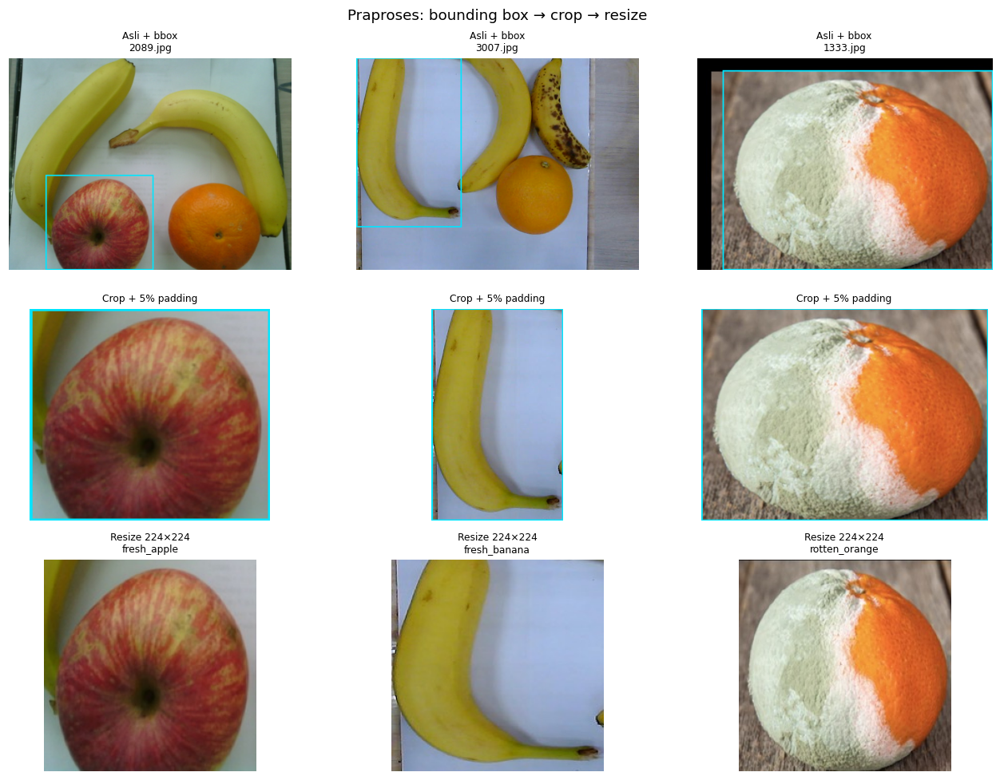

In [15]:
contoh = [crop_manifest[crop_manifest.label6 == lab].sample(1, random_state=SEED).iloc[0]
          for lab in ["fresh_apple", "fresh_banana", "rotten_orange"]]

fig, axes = plt.subplots(3, len(contoh), figsize=(4 * len(contoh), 9))
for col, r in enumerate(contoh):
    with Image.open(IMG_DIR / r["filename"]) as im:
        im = im.convert("RGB")
        x1, y1, x2, y2 = crop_box(r, im.width, im.height)
        ImageDraw.Draw(im).rectangle([x1, y1, x2, y2], outline="#00e5ff", width=3)
        axes[0, col].imshow(im)
        axes[0, col].set_title(f"Asli + bbox\n{r['filename']}", fontsize=8)
        axes[0, col].axis("off")
        axes[1, col].imshow(im.crop((x1, y1, x2, y2)))
        axes[1, col].set_title(f"Crop + {int(PAD*100)}% padding", fontsize=8)
        axes[1, col].axis("off")
    axes[2, col].imshow(Image.open(ROOT / r["crop_path"]))
    axes[2, col].set_title(f"Resize {IMG_SIZE}×{IMG_SIZE}\n{r['label6']}", fontsize=8)
    axes[2, col].axis("off")

fig.suptitle("Praproses: bounding box → crop → resize", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sebelum_sesudah.png", bbox_inches="tight")
plt.show()

### 2.5 Augmentasi (hanya train)

2026-10-26 16:10:13.003583: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


2026-10-26 16:10:13.083678: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 16:10:13.083870: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 16:10:13.093822: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 16:10:13.093887: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 16:10:13.093903: I external/local_xla/xla/stream_executor

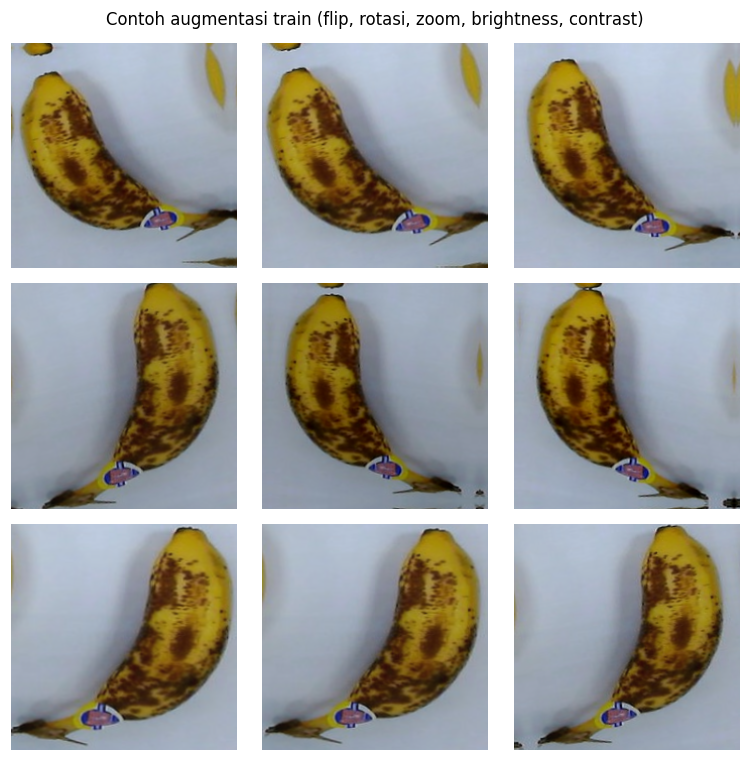

In [16]:
AUGMENT_GEOM = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.04, fill_mode="reflect"),
    tf.keras.layers.RandomZoom(0.08, fill_mode="reflect"),
], name="augmentasi_geometri")


def augment(image, label):
    image = AUGMENT_GEOM(image, training=True)
    image = tf.image.random_brightness(image, max_delta=0.08)
    image = tf.image.random_contrast(image, lower=0.92, upper=1.08)
    return tf.clip_by_value(image, 0.0, 1.0), label


r = crop_manifest[crop_manifest.label6 == "rotten_banana"].sample(1, random_state=SEED).iloc[0]
base = tf.image.convert_image_dtype(
    tf.io.decode_jpeg(tf.io.read_file(str(ROOT / r["crop_path"]))), tf.float32)
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax in axes.ravel():
    aug, _ = augment(base, 0)
    ax.imshow(tf.clip_by_value(aug, 0, 1)); ax.axis("off")
fig.suptitle("Contoh augmentasi train (flip, rotasi, zoom, brightness, contrast)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_augmentasi.png", bbox_inches="tight")
plt.show()

### 2.6 Pipeline `tf.data`

In [17]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_jpeg(raw, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label


def make_ds(split, training=False, batch_size=BATCH_SIZE):
    sub = crop_manifest[crop_manifest["split"] == split]
    paths = [str(ROOT / p) for p in sub["crop_path"]]
    labels = sub["label_id"].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)


train_ds = make_ds("train", training=True)
val_ds = make_ds("val", training=False)
test_ds = make_ds("test", training=False)

for nama, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    xb, yb = next(iter(ds))
    print(f"{nama:5s}: x={xb.shape} {xb.dtype} range=[{xb.numpy().min():.2f}, "
          f"{xb.numpy().max():.2f}] y={yb.shape}")

2026-10-26 16:10:20.831057: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node augmentasi_geometri_1/random_flip_1/add/_14}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:20.831556: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 7871323260688063524
2026-10-26 16:10:20.831673: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node augmentasi_geometri_1/random_flip_1/add/_14}}]]
	 [[GroupCrossDeviceControlEdges_0/NoOp/_21]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:20.831751: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 14873563916239929337
2026-10-26 16:10:20.831775: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Ke

train: x=(32, 224, 224, 3) <dtype: 'float32'> range=[0.00, 1.00] y=(32,)
val  : x=(32, 224, 224, 3) <dtype: 'float32'> range=[0.00, 1.00] y=(32,)


test : x=(32, 224, 224, 3) <dtype: 'float32'> range=[0.00, 1.00] y=(32,)


### 2.7 Sanity check pipeline

Val identik antar iterasi: True


2026-10-26 16:10:21.535148: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:21.535257: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]]
	 [[augmentasi_geometri_1/random_rotation_1/add/_18]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:21.535273: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 7871323260688063524
2026-10-26 16:10:21.535295: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-

2026-10-26 16:10:21.961150: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:21.961287: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:21.961319: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node augmentasi_geometri_1/random_flip_1/add/_14}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-26 16:10:21.961337: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 7871323260688063524
2026-10-26 16:10:21.961350: I tensorflow/core/framework/lo

Train berbeda antar iterasi: True


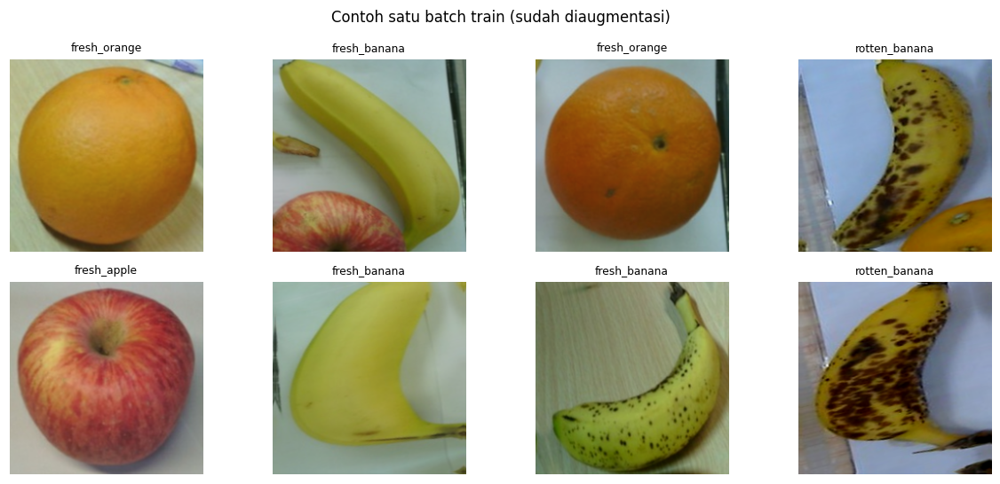

In [18]:
xb1, _ = next(iter(val_ds))
xb2, _ = next(iter(val_ds))
print("Val identik antar iterasi:", bool(tf.reduce_max(tf.abs(xb1 - xb2)) == 0))

xt1, yt1 = next(iter(train_ds))
xt2, _ = next(iter(train_ds))
print("Train berbeda antar iterasi:", bool(tf.reduce_max(tf.abs(xt1 - xt2)) > 0))

fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for ax, img, lab in zip(axes.ravel(), xt1[:8], yt1[:8]):
    ax.imshow(tf.clip_by_value(img, 0, 1))
    ax.set_title(CLASSES[int(lab)], fontsize=8); ax.axis("off")
fig.suptitle("Contoh satu batch train (sudah diaugmentasi)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_batch_train.png", bbox_inches="tight")
plt.show()

### 2.8 Ringkasan praproses

In [19]:
ringkasan2 = {
    "img_size": IMG_SIZE, "padding_bbox": PAD, "batch_size": BATCH_SIZE,
    "jumlah_crop": int(len(crop_manifest)),
    "per_split": {k: int(v) for k, v in crop_manifest["split"].value_counts().items()},
    "per_kelas": {k: int(v) for k, v in crop_manifest["label6"].value_counts().reindex(CLASSES).items()},
    "kelas": CLASSES,
    "class_weight": {r.label: float(r.class_weight) for r in tabel_bobot6.itertuples()},
    "input": {"skala": "[0, 1] float32",
              "cnn_baseline": "pakai langsung [0, 1]",
              "mobilenetv3": "include_preprocessing=False, x*2-1 -> [-1, 1]"},
    "augmentasi": ["RandomFlip(horizontal)", "RandomRotation(0.04)", "RandomZoom(0.08)",
                   "random_brightness(+-0.08)", "random_contrast(0.92-1.08)"],
}
(REPORT_DIR / "02_preprocessing_summary.json").write_text(json.dumps(ringkasan2, indent=2), encoding="utf-8")
print(json.dumps(ringkasan2, indent=2))

{
  "img_size": 224,
  "padding_bbox": 0.05,
  "batch_size": 32,
  "jumlah_crop": 6977,
  "per_split": {
    "train": 4871,
    "val": 1109,
    "test": 997
  },
  "per_kelas": {
    "fresh_apple": 1726,
    "rotten_apple": 178,
    "fresh_banana": 2248,
    "rotten_banana": 778,
    "fresh_orange": 1724,
    "rotten_orange": 323
  },
  "kelas": [
    "fresh_apple",
    "rotten_apple",
    "fresh_banana",
    "rotten_banana",
    "fresh_orange",
    "rotten_orange"
  ],
  "class_weight": {
    "fresh_apple": 0.678,
    "rotten_apple": 6.547,
    "fresh_banana": 0.517,
    "rotten_banana": 1.503,
    "fresh_orange": 0.67,
    "rotten_orange": 3.592
  },
  "input": {
    "skala": "[0, 1] float32",
    "cnn_baseline": "pakai langsung [0, 1]",
    "mobilenetv3": "include_preprocessing=False, x*2-1 -> [-1, 1]"
  },
  "augmentasi": [
    "RandomFlip(horizontal)",
    "RandomRotation(0.04)",
    "RandomZoom(0.08)",
    "random_brightness(+-0.08)",
    "random_contrast(0.92-1.08)"
  ]
}


## 3. CNN baseline (dilatih dari nol)

Arsitektur: 4 blok `Conv2D → BatchNorm → ReLU → MaxPool` (32, 64, 128, 256 filter),
`GlobalAveragePooling`, `Dense(128)`, dropout, lalu `softmax` 6 kelas.

Alasan:
- Sederhana dan cukup kuat sebagai pembanding transfer learning.
- `GlobalAveragePooling` menekan jumlah parameter dan overfitting.
- BatchNorm menstabilkan training; dropout 0.4 di kepala klasifikasi.
- Class weight dipakai karena rasio kelas 12,6×.

Metrik: accuracy, macro F1, per-class precision/recall/F1, dan confusion matrix.

### 3.1 Bangun model

In [20]:
def build_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=len(CLASSES)):
    inputs = keras.Input(shape=input_shape, name="citra")
    x = inputs
    for i, filters in enumerate((32, 64, 128, 256), start=1):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv{i}")(x)
        x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.Activation("relu", name=f"relu{i}")(x)
        x = layers.MaxPooling2D((2, 2), name=f"pool{i}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.4, name="drop1")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="prediksi")(x)
    return keras.Model(inputs, outputs, name="cnn_baseline")


model = build_cnn()
model.summary()
print(f"Total parameter: {model.count_params():,}")

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ citra (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediksi (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,526 (1.62 MB)

 Trainable params: 422,566 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Total parameter: 423,526


### 3.2 Training

In [21]:
EPOCHS = int(os.environ.get("FRESHSIGHT_EPOCHS", "25"))
SMOKE_TEST = os.environ.get("FRESHSIGHT_SMOKE", "0") == "1"
if SMOKE_TEST:
    EPOCHS = min(EPOCHS, 4)
print(f"Epochs: {EPOCHS} | smoke test: {SMOKE_TEST}")

callbacks = [
    keras.callbacks.ModelCheckpoint(MODEL_DIR / "cnn_baseline.keras", monitor="val_loss",
                                    save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                      min_lr=1e-5, verbose=1),
]
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=1)
train_time = time.time() - t0
print(f"Selesai {len(history.history['loss'])} epoch dalam {train_time/60:.1f} menit")

Epochs: 25 | smoke test: False
Epoch 1/25


I0000 00:00:1793031027.565949      72 service.cc:145] XLA service 0x3efef7f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793031027.566481      72 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6


2026-10-26 16:10:27.819297: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


2026-10-26 16:10:29.448908: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8906


I0000 00:00:1793031033.761471     289 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_928', 8 bytes spill stores, 8 bytes spill loads



...

152/153 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.9686 - loss: 0.1207


Epoch 25: val_loss improved from 0.03377 to 0.03322, saving model to /workspace/models/cnn_baseline.keras


153/153 ━━━━━━━━━━━━━━━━━━━━ 32s 211ms/step - accuracy: 0.9687 - loss: 0.1205 - val_accuracy: 0.9937 - val_loss: 0.0332 - learning_rate: 2.5000e-04


Restoring model weights from the end of the best epoch: 25.


Selesai 25 epoch dalam 16.6 menit


### 3.3 Kurva training

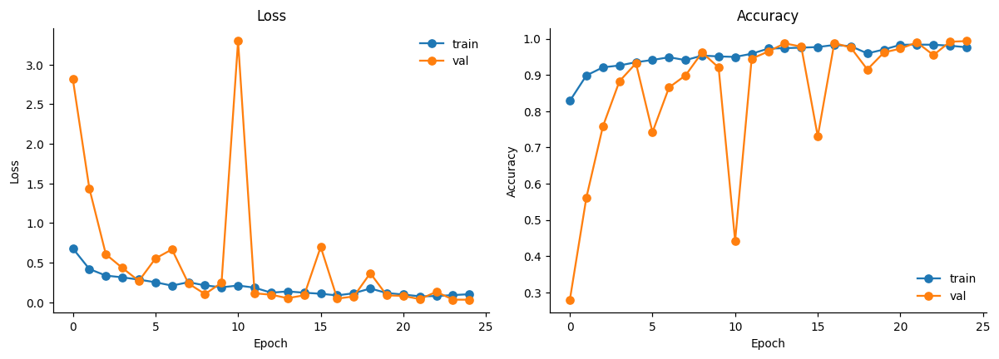

Val loss terbaik: 0.0332 (epoch 25) | val acc: 0.9937


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["loss"], marker="o", label="train")
axes[0].plot(history.history["val_loss"], marker="o", label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend(frameon=False)
axes[1].plot(history.history["accuracy"], marker="o", label="train")
axes[1].plot(history.history["val_accuracy"], marker="o", label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_kurva_cnn.png", bbox_inches="tight")
plt.show()

best_epoch = int(np.argmin(history.history["val_loss"]))
print(f"Val loss terbaik: {history.history['val_loss'][best_epoch]:.4f} "
      f"(epoch {best_epoch + 1}) | val acc: {history.history['val_accuracy'][best_epoch]:.4f}")

### 3.4 Evaluasi pada test set

Test loss     : 0.0208
Test accuracy : 0.9960
Macro F1      : 0.9906
Weighted F1   : 0.9960

               precision    recall  f1-score   support

  fresh_apple      1.000     0.987     0.993       230
 rotten_apple      0.931     1.000     0.964        27
 fresh_banana      0.997     1.000     0.999       354
rotten_banana      1.000     1.000     1.000       101
 fresh_orange      1.000     0.996     0.998       239
rotten_orange      0.979     1.000     0.989        46

     accuracy                          0.996       997
    macro avg      0.984     0.997     0.991       997
 weighted avg      0.996     0.996     0.996       997



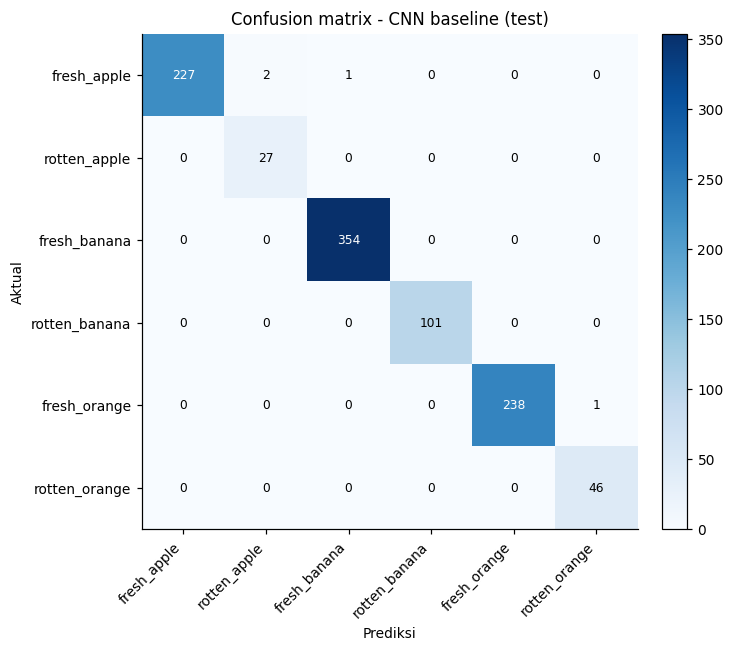

In [23]:
best_model = keras.models.load_model(MODEL_DIR / "cnn_baseline.keras")
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
probs = best_model.predict(test_ds, verbose=0)

test_sub = crop_manifest[crop_manifest.split == "test"].reset_index(drop=True)
y_true = test_sub["label_id"].to_numpy()
y_pred = probs.argmax(axis=1)

macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc:.4f}")
print(f"Macro F1      : {macro_f1:.4f}")
print(f"Weighted F1   : {weighted_f1:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticklabels(CLASSES)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Confusion matrix - CNN baseline (test)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_confusion_cnn.png", bbox_inches="tight")
plt.show()

### 3.5 Analisis error

Salah prediksi: 4 / 997 (0.4%)


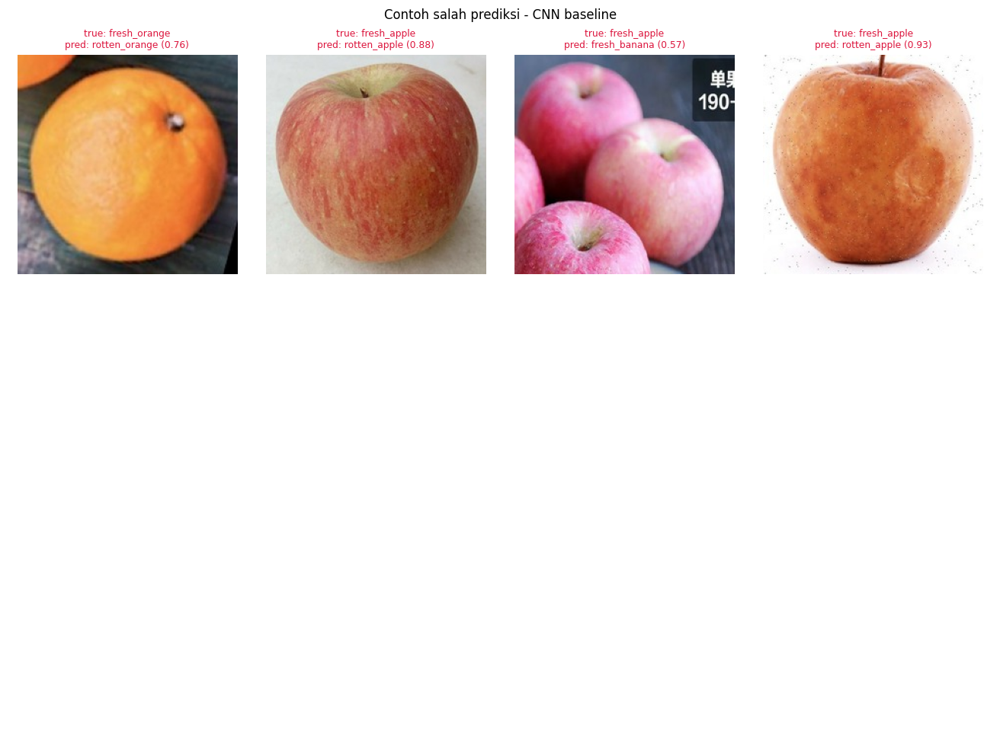

Pasangan salah prediksi terbanyak:
  fresh_apple -> rotten_apple: 2
  fresh_orange -> rotten_orange: 1
  fresh_apple -> fresh_banana: 1


In [24]:
salah = np.where(y_pred != y_true)[0]
print(f"Salah prediksi: {len(salah)} / {len(y_true)} ({len(salah)/len(y_true)*100:.1f}%)")

pilih = salah[:12]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, i in zip(axes.ravel(), pilih):
    ax.imshow(Image.open(ROOT / test_sub.loc[i, "crop_path"]))
    ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} "
                 f"({probs[i].max():.2f})", fontsize=8, color="crimson")
    ax.axis("off")
for ax in axes.ravel()[len(pilih):]:
    ax.axis("off")
fig.suptitle("Contoh salah prediksi - CNN baseline")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_error_cnn.png", bbox_inches="tight")
plt.show()

# Kelas yang paling sering tertukar
pasangan = collections.Counter((CLASSES[t], CLASSES[p]) for t, p in zip(y_true, y_pred) if t != p)
print("Pasangan salah prediksi terbanyak:")
for (t, p), c in pasangan.most_common(5):
    print(f"  {t} -> {p}: {c}")

### 3.6 Simpan hasil

In [25]:
rep = classification_report(y_true, y_pred, target_names=CLASSES, digits=4,
                            output_dict=True, zero_division=0)
hasil = {
    "model": "cnn_baseline",
    "epochs_run": len(history.history["loss"]),
    "epochs_planned": EPOCHS,
    "smoke_test": bool(SMOKE_TEST),
    "train_time_s": round(train_time, 1),
    "params": int(model.count_params()),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_acc),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "per_class": {k: ({m: float(v) for m, v in d.items()} if isinstance(d, dict) else float(d))
                  for k, d in rep.items()},
    "confusion_matrix": cm.tolist(),
    "classes": CLASSES,
}
(REPORT_DIR / "03_cnn_baseline_metrics.json").write_text(json.dumps(hasil, indent=2), encoding="utf-8")
pd.DataFrame(history.history).to_csv(REPORT_DIR / "03_cnn_baseline_history.csv", index=False)
print("Tersimpan:", REPORT_DIR / "03_cnn_baseline_metrics.json")
print(json.dumps({k: hasil[k] for k in ["model", "epochs_run", "params", "test_accuracy",
                                        "macro_f1", "weighted_f1"]}, indent=2))

Tersimpan: /workspace/reports/03_cnn_baseline_metrics.json
{
  "model": "cnn_baseline",
  "epochs_run": 25,
  "params": 423526,
  "test_accuracy": 0.9959879517555237,
  "macro_f1": 0.9905769335661847,
  "weighted_f1": 0.9960189576762841
}


## 4. MobileNetV3 — transfer learning dua tahap

MobileNetV3 memakai *depthwise separable convolution* sehingga efisien untuk model berskala
besar; pada proyek ini parameternya (942 ribu) justru lebih besar daripada CNN baseline
(424 ribu), tetapi bobot ImageNet memberi representasi awal yang kuat untuk data terbatas.

**Dua tahap:**
1. **Stage 1 — freeze backbone, latih head.** Backbone tidak berubah; hanya `GAP → Dropout →
   Dense` yang dilatih. Learning rate 1e-3.
2. **Stage 2 — fine-tuning lapisan atas.** Backbone dibuka sebagian (40 layer terakhir),
   learning rate kecil (1e-4). **BatchNorm tetap `trainable=False`** agar statistik
   ImageNet tidak rusak oleh batch kecil.

Input pipeline tetap **[0, 1]**; model menambahkan `Rescaling(2, offset=-1)` agar sesuai
dengan MobileNetV3 (`include_preprocessing=False`). Ini mencegah normalisasi ganda.

### 4.1 Bangun model

In [26]:
def build_mobilenetv3(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=len(CLASSES),
                      alpha=1.0, dropout=0.3):
    backbone = keras.applications.MobileNetV3Small(
        include_top=False, weights="imagenet", include_preprocessing=False,
        input_shape=input_shape, alpha=alpha)
    inputs = keras.Input(shape=input_shape, name="citra")
    x = layers.Rescaling(2.0, offset=-1.0, name="ke_minus1_1")(inputs)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="prediksi")(x)
    return keras.Model(inputs, outputs, name="mobilenetv3_freshsight"), backbone


model_mnv3, backbone = build_mobilenetv3()
model_mnv3.summary()
print(f"Total parameter     : {model_mnv3.count_params():,}")
print(f"Trainable (stage 1) : {sum(int(np.prod(w.shape)) for w in model_mnv3.trainable_weights):,}")

Model: "mobilenetv3_freshsight"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ citra (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_minus1_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobilenetV3small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediksi (Dense)                │ (None, 6)              │         3,462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 942,582 (3.60 MB)

 Trainable params: 930,470 (3.55 MB)

 Non-trainable params: 12,112 (47.31 KB)

Total parameter     : 942,582
Trainable (stage 1) : 930,470


### 4.2 Stage 1 — latih head (backbone frozen)

In [27]:
EPOCHS1 = int(os.environ.get("FRESHSIGHT_MNV3_EPOCHS1", "10"))
if os.environ.get("FRESHSIGHT_SMOKE", "0") == "1":
    EPOCHS1 = min(EPOCHS1, 2)
print(f"Stage 1 epochs: {EPOCHS1}")

backbone.trainable = False
model_mnv3.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cb1 = [
    keras.callbacks.ModelCheckpoint(MODEL_DIR / "mobilenetv3_stage1.keras",
                                    monitor="val_loss", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                      min_lr=1e-6, verbose=1),
]
t0 = time.time()
hist1 = model_mnv3.fit(train_ds, validation_data=val_ds, epochs=EPOCHS1,
                       class_weight=CLASS_WEIGHT, callbacks=cb1, verbose=1)
t1 = time.time() - t0
print(f"Stage 1 selesai dalam {t1/60:.1f} menit")

Stage 1 epochs: 10
Epoch 1/10


2026-10-26 16:27:29.114854: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267968 bytes after encountering the first element of size 19267968 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


  1/153 ━━━━━━━━━━━━━━━━━━━━ 1:10:30 28s/step - accuracy: 0.0000e+00 - loss: 2.4026

  2/153 ━━━━━━━━━━━━━━━━━━━━ 13s 89ms/step - accuracy: 0.0703 - loss: 2.7213       

  3/153 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.1094 - loss: 2.6310

...

152/153 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.9880 - loss: 0.0621


Epoch 10: val_loss improved from 0.04703 to 0.04331, saving model to /workspace/models/mobilenetv3_stage1.keras


153/153 ━━━━━━━━━━━━━━━━━━━━ 29s 189ms/step - accuracy: 0.9880 - loss: 0.0620 - val_accuracy: 0.9919 - val_loss: 0.0433 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 10.


Stage 1 selesai dalam 6.3 menit


### 4.3 Stage 2 — fine-tuning lapisan atas

In [28]:
EPOCHS2 = int(os.environ.get("FRESHSIGHT_MNV3_EPOCHS2", "10"))
if os.environ.get("FRESHSIGHT_SMOKE", "0") == "1":
    EPOCHS2 = min(EPOCHS2, 1)
print(f"Stage 2 epochs: {EPOCHS2}")

backbone.trainable = True
for layer in backbone.layers[:-40]:
    layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable2 = sum(int(np.prod(w.shape)) for w in model_mnv3.trainable_weights)
print(f"Trainable (stage 2): {trainable2:,}")

model_mnv3.compile(optimizer=keras.optimizers.Adam(1e-4),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cb2 = [
    keras.callbacks.ModelCheckpoint(MODEL_DIR / "mobilenetv3_stage2.keras",
                                    monitor="val_loss", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                      min_lr=1e-6, verbose=1),
]
t0 = time.time()
hist2 = model_mnv3.fit(train_ds, validation_data=val_ds, epochs=EPOCHS2,
                       class_weight=CLASS_WEIGHT, callbacks=cb2, verbose=1)
t2 = time.time() - t0
print(f"Stage 2 selesai dalam {t2/60:.1f} menit")

Stage 2 epochs: 10
Trainable (stage 2): 711,438


Epoch 1/10


2026-10-26 16:33:51.193876: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267968 bytes after encountering the first element of size 19267968 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


  1/153 ━━━━━━━━━━━━━━━━━━━━ 1:05:22 26s/step - accuracy: 1.0000 - loss: 0.0375

  2/153 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.9922 - loss: 0.0658    

...


Epoch 6: val_loss did not improve from 0.01919


153/153 ━━━━━━━━━━━━━━━━━━━━ 25s 161ms/step - accuracy: 0.9981 - loss: 0.0108 - val_accuracy: 0.9964 - val_loss: 0.0200 - learning_rate: 5.0000e-05


Epoch 6: early stopping


Restoring model weights from the end of the best epoch: 3.


Stage 2 selesai dalam 3.6 menit


### 4.4 Kurva training (stage 1 + stage 2)

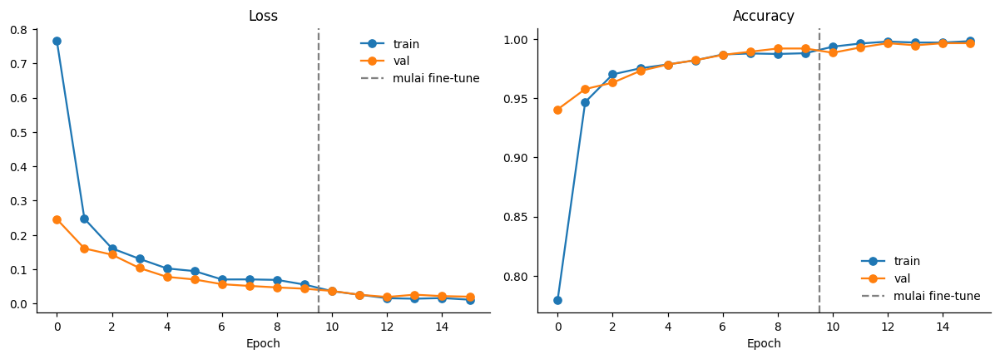

Val loss terbaik: 0.0192 (epoch total 13) | val acc: 0.9964


In [29]:
loss = hist1.history["loss"] + hist2.history["loss"]
val_loss = hist1.history["val_loss"] + hist2.history["val_loss"]
acc = hist1.history["accuracy"] + hist2.history["accuracy"]
val_acc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
batas = len(hist1.history["loss"]) - 0.5

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(loss, marker="o", label="train")
axes[0].plot(val_loss, marker="o", label="val")
axes[0].axvline(batas, color="gray", linestyle="--", label="mulai fine-tune")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(frameon=False)
axes[1].plot(acc, marker="o", label="train")
axes[1].plot(val_acc, marker="o", label="val")
axes[1].axvline(batas, color="gray", linestyle="--", label="mulai fine-tune")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_kurva_mobilenet.png", bbox_inches="tight")
plt.show()

best_epoch = int(np.argmin(val_loss))
print(f"Val loss terbaik: {val_loss[best_epoch]:.4f} (epoch total {best_epoch + 1}) "
      f"| val acc: {val_acc[best_epoch]:.4f}")

### 4.5 Evaluasi test set

> Catatan: waktu inferensi di sel ini diukur melalui `predict(test_ds)` sehingga termasuk overhead pipeline data. Angka perbandingan murni (setelah warm-up, tanpa pipeline) ada di Bagian 5.

I0000 00:00:1793032649.441261    1772 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_1321', 80 bytes spill stores, 80 bytes spill loads



Test loss     : 0.0246
Test accuracy : 0.9920
Macro F1      : 0.9871
Weighted F1   : 0.9921
Inferensi     : 13.4 ms/gambar (CPU)

               precision    recall  f1-score   support

  fresh_apple      1.000     0.991     0.996       230
 rotten_apple      0.931     1.000     0.964        27
 fresh_banana      1.000     0.983     0.991       354
rotten_banana      0.944     1.000     0.971       101
 fresh_orange      1.000     1.000     1.000       239
rotten_orange      1.000     1.000     1.000        46

     accuracy                          0.992       997
    macro avg      0.979     0.996     0.987       997
 weighted avg      0.992     0.992     0.992       997



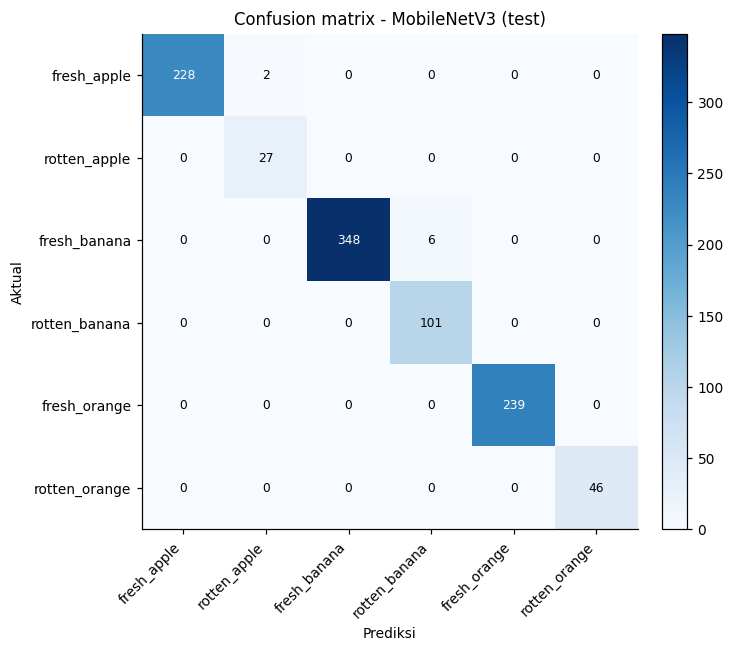

In [30]:
best_mnv3 = keras.models.load_model(MODEL_DIR / "mobilenetv3_stage2.keras")
test_loss4, test_acc4 = best_mnv3.evaluate(test_ds, verbose=0)

t0 = time.time()
probs4 = best_mnv3.predict(test_ds, verbose=0)
infer_s = time.time() - t0

y_true4 = test_sub["label_id"].to_numpy()
y_pred4 = probs4.argmax(axis=1)
macro_f14 = f1_score(y_true4, y_pred4, average="macro")
weighted_f14 = f1_score(y_true4, y_pred4, average="weighted")

print(f"Test loss     : {test_loss4:.4f}")
print(f"Test accuracy : {test_acc4:.4f}")
print(f"Macro F1      : {macro_f14:.4f}")
print(f"Weighted F1   : {weighted_f14:.4f}")
print(f"Inferensi     : {infer_s / len(y_true4) * 1000:.1f} ms/gambar (CPU)")
print()
print(classification_report(y_true4, y_pred4, target_names=CLASSES, digits=3, zero_division=0))

cm4 = confusion_matrix(y_true4, y_pred4, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm4, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
for i in range(cm4.shape[0]):
    for j in range(cm4.shape[1]):
        ax.text(j, i, cm4[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm4[i, j] > cm4.max() / 2 else "black")
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Confusion matrix - MobileNetV3 (test)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_confusion_mobilenet.png", bbox_inches="tight")
plt.show()

### 4.6 Simpan hasil

In [31]:
best_mnv3.save(MODEL_DIR / "mobilenetv3.keras")
ukuran_mb = (MODEL_DIR / "mobilenetv3.keras").stat().st_size / (1024 * 1024)

rep4 = classification_report(y_true4, y_pred4, target_names=CLASSES, digits=4,
                             output_dict=True, zero_division=0)
hasil4 = {
    "model": "mobilenetv3_small",
    "stage1_epochs": len(hist1.history["loss"]),
    "stage2_epochs": len(hist2.history["loss"]),
    "stage1_time_s": round(t1, 1),
    "stage2_time_s": round(t2, 1),
    "params": int(best_mnv3.count_params()),
    "size_mb": round(ukuran_mb, 2),
    "test_loss": float(test_loss4),
    "test_accuracy": float(test_acc4),
    "macro_f1": float(macro_f14),
    "weighted_f1": float(weighted_f14),
    "infer_ms_per_image": round(infer_s / len(y_true4) * 1000, 2),
    "per_class": {k: ({m: float(v) for m, v in d.items()} if isinstance(d, dict) else float(d))
                  for k, d in rep4.items()},
    "confusion_matrix": cm4.tolist(),
    "classes": CLASSES,
}
(REPORT_DIR / "04_mobilenetv3_metrics.json").write_text(json.dumps(hasil4, indent=2), encoding="utf-8")
pd.DataFrame(hist1.history).to_csv(REPORT_DIR / "04_history_stage1.csv", index=False)
pd.DataFrame(hist2.history).to_csv(REPORT_DIR / "04_history_stage2.csv", index=False)
print("Tersimpan:", REPORT_DIR / "04_mobilenetv3_metrics.json")
print(json.dumps({k: hasil4[k] for k in ["model", "params", "size_mb", "test_accuracy",
                                        "macro_f1", "weighted_f1", "infer_ms_per_image"]}, indent=2))

Tersimpan: /workspace/reports/04_mobilenetv3_metrics.json
{
  "model": "mobilenetv3_small",
  "params": 942582,
  "size_mb": 11.3,
  "test_accuracy": 0.9919759035110474,
  "macro_f1": 0.9870876232775796,
  "weighted_f1": 0.9920684502601652,
  "infer_ms_per_image": 13.43
}


## 5. Perbandingan CNN baseline vs MobileNetV3

Kedua model dievaluasi pada **test set yang sama** (997 objek, 6 kelas, bebas leakage
gambar/klaster). Waktu inferensi diukur setelah satu batch pemanasan, di CPU yang sama.

### 5.1 Muat model & ukur metrik

In [32]:
def evaluasi(model, ds, y_true, nama, size_mb):
    _ = model.predict(ds.take(1), verbose=0)          # warm-up
    t0 = time.time()
    probs = model.predict(ds, verbose=0)
    dur = time.time() - t0
    pred = probs.argmax(axis=1)
    return {
        "model": nama,
        "accuracy": accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "weighted_f1": f1_score(y_true, pred, average="weighted"),
        "params": int(model.count_params()),
        "size_mb": round(size_mb, 2),
        "infer_ms": dur / len(y_true) * 1000,
    }, probs, pred


cnn = keras.models.load_model(MODEL_DIR / "cnn_baseline.keras")
mnv3 = keras.models.load_model(MODEL_DIR / "mobilenetv3.keras")

res_cnn, probs_cnn, pred_cnn = evaluasi(
    cnn, test_ds, y_true, "CNN baseline",
    (MODEL_DIR / "cnn_baseline.keras").stat().st_size / 1e6)
res_mnv3, probs_mnv3, pred_mnv3 = evaluasi(
    mnv3, test_ds, y_true, "MobileNetV3",
    (MODEL_DIR / "mobilenetv3.keras").stat().st_size / 1e6)

tabel_banding = pd.DataFrame([res_cnn, res_mnv3])
tabel_banding["accuracy"] = tabel_banding["accuracy"].round(4)
tabel_banding["macro_f1"] = tabel_banding["macro_f1"].round(4)
tabel_banding["weighted_f1"] = tabel_banding["weighted_f1"].round(4)
tabel_banding["infer_ms"] = tabel_banding["infer_ms"].round(2)
display(tabel_banding)

2026-10-26 16:38:03.516238: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


2026-10-26 16:38:04.527828: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


2026-10-26 16:38:06.230278: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2026-10-26 16:38:06.230646: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


2026-10-26 16:38:10.095076: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


,model,accuracy,macro_f1,weighted_f1,params,size_mb,infer_ms
0,CNN baseline,0.996,0.9906,0.9960,423526,5.16,1.67
1,MobileNetV3,0.992,0.9871,0.9921,942582,11.84,5.55


### 5.2 Grafik perbandingan

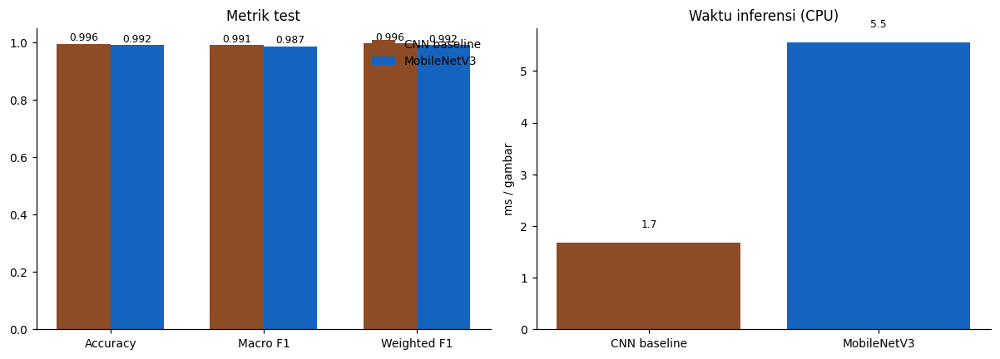

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metrik = ["accuracy", "macro_f1", "weighted_f1"]
x = np.arange(len(metrik))
w = 0.35
axes[0].bar(x - w/2, [res_cnn[m] for m in metrik], w, label="CNN baseline", color="#8d4b26")
axes[0].bar(x + w/2, [res_mnv3[m] for m in metrik], w, label="MobileNetV3", color="#1565c0")
axes[0].set_xticks(x); axes[0].set_xticklabels(["Accuracy", "Macro F1", "Weighted F1"])
axes[0].set_ylim(0, 1.05); axes[0].set_title("Metrik test")
axes[0].legend(frameon=False)
for i, (a, b) in enumerate(zip([res_cnn[m] for m in metrik], [res_mnv3[m] for m in metrik])):
    axes[0].text(i - w/2, a + 0.01, f"{a:.3f}", ha="center", fontsize=8)
    axes[0].text(i + w/2, b + 0.01, f"{b:.3f}", ha="center", fontsize=8)

axes[1].bar(["CNN baseline", "MobileNetV3"], [res_cnn["infer_ms"], res_mnv3["infer_ms"]],
            color=["#8d4b26", "#1565c0"])
axes[1].set_ylabel("ms / gambar"); axes[1].set_title("Waktu inferensi (CPU)")
for i, v in enumerate([res_cnn["infer_ms"], res_mnv3["infer_ms"]]):
    axes[1].text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_perbandingan.png", bbox_inches="tight")
plt.show()

### 5.3 F1 per kelas

,CNN baseline,MobileNetV3,support
fresh_apple,0.993,0.996,230.0
rotten_apple,0.964,0.964,27.0
fresh_banana,0.999,0.991,354.0
rotten_banana,1.000,0.971,101.0
fresh_orange,0.998,1.000,239.0
rotten_orange,0.989,1.000,46.0


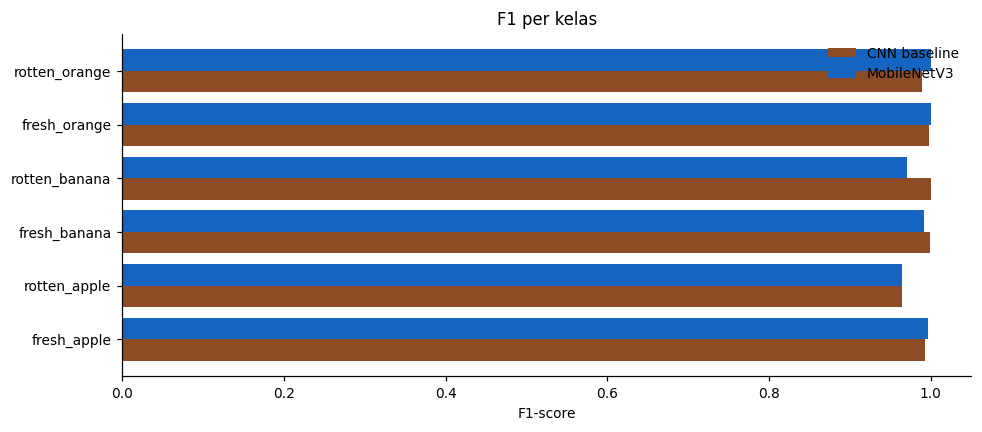

In [34]:
rep_cnn = classification_report(y_true, pred_cnn, target_names=CLASSES,
                                output_dict=True, zero_division=0)
rep_mnv3 = classification_report(y_true, pred_mnv3, target_names=CLASSES,
                                 output_dict=True, zero_division=0)

tabel_f1 = pd.DataFrame({
    "CNN baseline": [rep_cnn[c]["f1-score"] for c in CLASSES],
    "MobileNetV3": [rep_mnv3[c]["f1-score"] for c in CLASSES],
    "support": [rep_cnn[c]["support"] for c in CLASSES],
}, index=CLASSES).round(3)
display(tabel_f1)

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(CLASSES))
ax.barh(y - 0.2, tabel_f1["CNN baseline"], 0.4, label="CNN baseline", color="#8d4b26")
ax.barh(y + 0.2, tabel_f1["MobileNetV3"], 0.4, label="MobileNetV3", color="#1565c0")
ax.set_yticks(y); ax.set_yticklabels(CLASSES)
ax.set_xlim(0, 1.05); ax.set_xlabel("F1-score"); ax.legend(frameon=False)
ax.set_title("F1 per kelas")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_f1_per_kelas.png", bbox_inches="tight")
plt.show()

### 5.4 Analisis error: di mana model berbeda?

In [35]:
salah_cnn = pred_cnn != y_true
salah_mnv3 = pred_mnv3 != y_true
keduanya = salah_cnn & salah_mnv3
hanya_cnn = salah_cnn & ~salah_mnv3
hanya_mnv3 = ~salah_cnn & salah_mnv3

print(f"Salah CNN          : {salah_cnn.sum():3d} / {len(y_true)} ({salah_cnn.mean()*100:.1f}%)")
print(f"Salah MobileNetV3  : {salah_mnv3.sum():3d} / {len(y_true)} ({salah_mnv3.mean()*100:.1f}%)")
print(f"Keduanya salah     : {keduanya.sum():3d}")
print(f"Hanya CNN salah    : {hanya_cnn.sum():3d}")
print(f"Hanya MNV3 salah   : {hanya_mnv3.sum():3d}")
print(f"Tumpang tindih error (Jaccard): {keduanya.sum() / max((salah_cnn | salah_mnv3).sum(), 1):.3f}")

Salah CNN          :   4 / 997 (0.4%)
Salah MobileNetV3  :   8 / 997 (0.8%)
Keduanya salah     :   1
Hanya CNN salah    :   3
Hanya MNV3 salah   :   7
Tumpang tindih error (Jaccard): 0.091


### 5.5 Contoh kasus

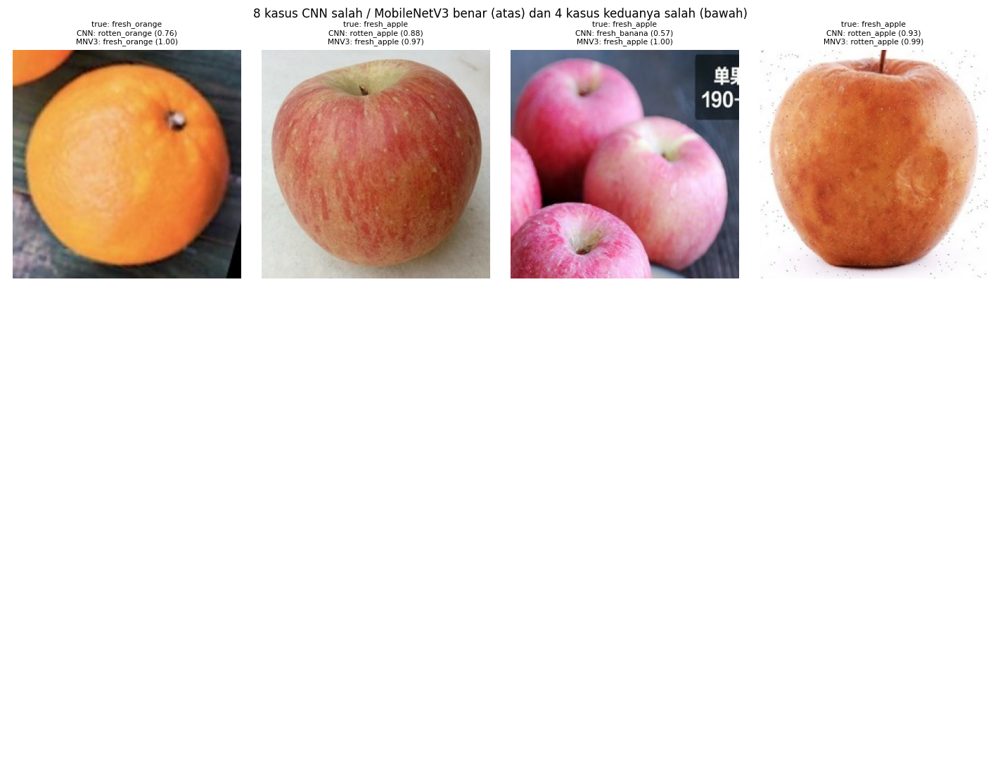


CNN - kesalahan terbanyak:
  fresh_apple -> rotten_apple: 2
  fresh_orange -> rotten_orange: 1
  fresh_apple -> fresh_banana: 1

MobileNetV3 - kesalahan terbanyak:
  fresh_banana -> rotten_banana: 6
  fresh_apple -> rotten_apple: 2


In [36]:
# 8 kasus CNN salah tetapi MobileNetV3 benar + 4 kasus keduanya salah
pilih = list(np.where(hanya_cnn)[0][:8]) + list(np.where(keduanya)[0][:4])
pilih = pilih[:12]

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, i in zip(axes.ravel(), pilih):
    ax.imshow(Image.open(ROOT / test_sub.loc[i, "crop_path"]))
    ax.set_title(
        f"true: {CLASSES[y_true[i]]}\n"
        f"CNN: {CLASSES[pred_cnn[i]]} ({probs_cnn[i].max():.2f})\n"
        f"MNV3: {CLASSES[pred_mnv3[i]]} ({probs_mnv3[i].max():.2f})",
        fontsize=7)
    ax.axis("off")
for ax in axes.ravel()[len(pilih):]:
    ax.axis("off")
fig.suptitle("8 kasus CNN salah / MobileNetV3 benar (atas) dan 4 kasus keduanya salah (bawah)",
             fontsize=11)
fig.subplots_adjust(top=0.90)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_contoh_error.png", bbox_inches="tight")
plt.show()

# Pasangan kesalahan terbanyak per model
for nama, pred in [("CNN", pred_cnn), ("MobileNetV3", pred_mnv3)]:
    pasangan = collections.Counter((CLASSES[t], CLASSES[p])
                                   for t, p in zip(y_true, pred) if t != p)
    print(f"\n{nama} - kesalahan terbanyak:")
    for (t, p), n in pasangan.most_common(4):
        print(f"  {t} -> {p}: {n}")

### 5.6 Simpan hasil

In [37]:
hasil5 = {
    "test_size": int(len(y_true)),
    "comparison": tabel_banding.to_dict(orient="records"),
    "errors": {
        "cnn": int(salah_cnn.sum()),
        "mobilenetv3": int(salah_mnv3.sum()),
        "both": int(keduanya.sum()),
        "only_cnn": int(hanya_cnn.sum()),
        "only_mobilenetv3": int(hanya_mnv3.sum()),
        "jaccard": float(keduanya.sum() / max((salah_cnn | salah_mnv3).sum(), 1)),
    },
    "f1_per_class": tabel_f1.reset_index().rename(columns={"index": "label"}).to_dict(orient="records"),
}
(REPORT_DIR / "05_comparison.json").write_text(json.dumps(hasil5, indent=2), encoding="utf-8")
tabel_banding.to_csv(REPORT_DIR / "05_model_comparison.csv", index=False)
tabel_f1.to_csv(REPORT_DIR / "05_f1_per_class.csv")
print("Tersimpan:", REPORT_DIR / "05_comparison.json")

Tersimpan: /workspace/reports/05_comparison.json


### Interpretasi

- Pada latihan penuh (CNN 25 epoch; MobileNetV3 10 epoch stage 1 + 6 epoch stage 2 karena
  EarlyStopping), kedua model sangat kompetitif. CNN baseline sedikit lebih tinggi:
  accuracy **99,60%** vs **99,20%**, macro F1 **0,991** vs **0,987**.
- Per kelas, CNN unggul pada `fresh_banana` (F1 0,999 vs 0,991) dan `rotten_banana`
  (1,000 vs 0,971); MobileNetV3 unggul pada `fresh_apple` (0,996 vs 0,993),
  `fresh_orange` (1,000 vs 0,998), dan `rotten_orange` (1,000 vs 0,989);
  `rotten_apple` setara (0,964).
- Trade-off: MobileNetV3 ~2,3x lebih besar (11,84 vs 5,16 MB) dan lebih lambat di CPU
  pada pengukuran ini (5,55 vs 1,67 ms/gambar). CNN baseline lebih ringkas dan cepat,
  sekaligus akurasinya sedikit lebih tinggi.
- Model dengan metrik terbaik adalah **CNN baseline**. MobileNetV3 tetap dipakai untuk
  Grad-CAM karena mewakili pendekatan transfer learning dan menyediakan feature map 7x7;
  bukan karena metriknya lebih tinggi.
- Imbalance data masih **12,6x** (`rotten_apple` 178 vs `fresh_banana` 2.248 objek). Bobot
  kelas 0,52-6,55 menahan bias ke kelas mayoritas; efek sisanya terlihat pada precision
  `rotten_apple` 0,931 (2 apel segar disebut busuk) dan 6 `fresh_banana` yang disebut
  `rotten_banana` oleh MobileNetV3.

## 6. Explainability: Grad-CAM + analisis defek

Model menjawab **apa** (fresh/rotten), bagian ini menjawab **mengapa**. Dua lapis:

1. **Grad-CAM** pada MobileNetV3 — peta area yang paling berpengaruh terhadap keputusan.
2. **Analisis defek berbasis OpenCV** — segmentasi buah, rasio bercak gelap/cokelat,
   penyimpangan warna dari referensi segar, tekstur (varians Laplacian), dan jumlah bercak.

Ambang defek **dikalibrasi dari data train** (bukan ditebak): untuk tiap buah dihitung
statistik `fresh` vs `rotten`, lalu ambang diambil di tengah keduanya.

> Lapisan kedua bersifat **heuristik**, bukan penjelasan kausal. Evaluasi kualitatif
> dilakukan pada 12 contoh (6 fresh, 6 rotten).

### 6.1 Muat model & Grad-CAM

Feature map: (None, 7, 7, 576) | output: (None, 6)


Prediksi: rotten_banana (1.000)


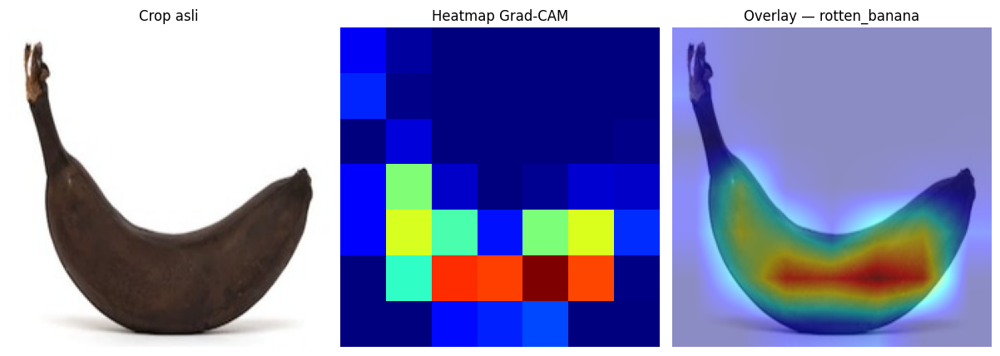

2026-10-26 16:38:30.049859: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


Test accuracy: 0.9920 | salah: 8


In [38]:
import cv2
import textwrap

train_sub = crop_manifest[crop_manifest.split == "train"].reset_index(drop=True)
test_sub = crop_manifest[crop_manifest.split == "test"].reset_index(drop=True)

model = keras.models.load_model(MODEL_DIR / "mobilenetv3.keras")
backbone = next(l for l in model.layers if l.name.lower().startswith("mobilenet"))

# Sub-model yang mengembalikan feature map terakhir + prediksi, berbagi bobot.
bi = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="backbone_input")
feat_out = backbone(bi, training=False)
if isinstance(feat_out, (list, tuple)):  # Keras 3.0.x mengembalikan list
    feat_out = feat_out[0]
backbone_conv = keras.Model(bi, feat_out, name="backbone_feature")

inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="citra")
x = keras.layers.Rescaling(2.0, offset=-1.0, name="ke_minus1_1")(inp)
feat = backbone_conv(x)
if isinstance(feat, (list, tuple)):
    feat = feat[0]
y = model.get_layer("gap")(feat)
if isinstance(y, (list, tuple)):
    y = y[0]
y = model.get_layer("prediksi")(y)
grad_model = keras.Model(inp, [feat, y], name="gradcam_model")
print("Feature map:", feat.shape, "| output:", y.shape)


def gradcam(img, class_idx=None):
    """img: float32 [0,1] (224,224,3). Returns heatmap, class_idx, probs."""
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv, preds = grad_model(x, training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.reduce_sum(conv[0] * pooled, axis=-1)
    heat = tf.maximum(heat, 0)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy(), class_idx, preds.numpy()[0]


def overlay_heatmap(img, heat, alpha=0.45):
    heat = cv2.resize(heat, (img.shape[1], img.shape[0]))
    heat = np.uint8(255 * heat)
    heat = cv2.applyColorMap(heat, cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB) / 255.0
    return np.clip((1 - alpha) * img + alpha * heat, 0, 1)


contoh = test_sub[test_sub.label6 == "rotten_banana"].iloc[0]
img_bgr = cv2.resize(cv2.imread(str(ROOT / contoh.crop_path)), (IMG_SIZE, IMG_SIZE))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) / 255.0
heat, idx, probs = gradcam(img_rgb)
print("Prediksi:", CLASSES[idx], f"({probs[idx]:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(img_rgb); axes[0].set_title("Crop asli"); axes[0].axis("off")
axes[1].imshow(heat, cmap="jet"); axes[1].set_title("Heatmap Grad-CAM"); axes[1].axis("off")
axes[2].imshow(overlay_heatmap(img_rgb, heat))
axes[2].set_title(f"Overlay — {CLASSES[idx]}"); axes[2].axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_gradcam_demo.png", bbox_inches="tight")
plt.show()

# Prediksi seluruh test untuk memilih contoh benar + salah
def _load(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32) / 255.0, label


test_ds_all = (
    tf.data.Dataset.from_tensor_slices(
        ([str(ROOT / p) for p in test_sub.crop_path], test_sub.label_id.to_numpy(np.int32)))
    .map(_load, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32).prefetch(tf.data.AUTOTUNE)
)
probs_all = model.predict(test_ds_all, verbose=0)
pred_all = probs_all.argmax(axis=1)
y_all = test_sub.label_id.to_numpy()
print(f"Test accuracy: {(pred_all == y_all).mean():.4f} | salah: {(pred_all != y_all).sum()}")

### 6.2 Segmentasi buah & fitur defek

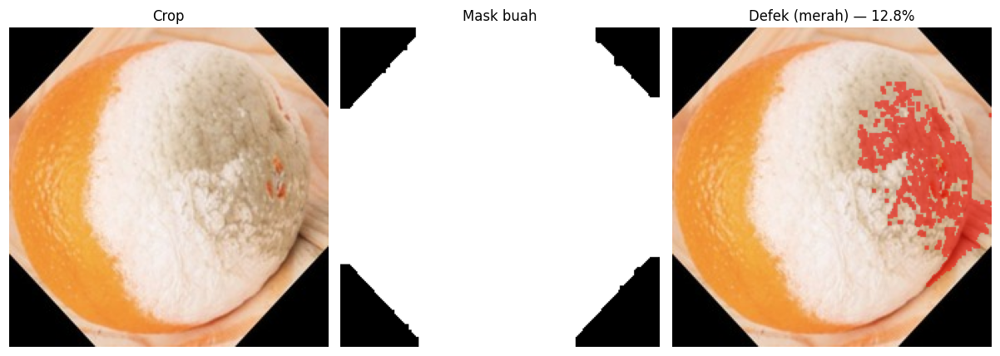

rasio_defek=0.128 tekstur=1385.3 bercak=7 terbesar=12.3% lokasi=kanan


In [39]:
def fruit_mask(bgr):
    """Segmentasi kasar: warna jenuh + komponen terbesar, fallback elips tengah."""
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    s, v = hsv[..., 1], hsv[..., 2]
    m = ((s > 45) & (v > 35)).astype(np.uint8) * 255
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8), iterations=2)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8), iterations=1)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        c = max(cnts, key=cv2.contourArea)
        m = np.zeros_like(m)
        cv2.drawContours(m, [c], -1, 255, -1)
    if m.mean() < 20:
        m = np.zeros_like(m)
        cv2.ellipse(m, (112, 112), (92, 92), 0, 0, 360, 255, -1)
    return m > 0


def defect_mask(bgr, mask):
    """Bercak gelap/cokelat relatif terhadap warna buah."""
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0].astype(float), hsv[..., 1].astype(float), hsv[..., 2].astype(float)
    med = np.median(v[mask]) if mask.any() else 128.0
    gelap = (v < 0.55 * med) | (v < 45)
    cokelat = (h >= 5) & (h <= 35) & (s > 50) & (v < 0.85 * med)
    d = ((gelap | cokelat) & mask).astype(np.uint8)
    d = cv2.morphologyEx(d, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    return d > 0


def fitur_defek(bgr):
    mask = fruit_mask(bgr)
    # Erosi tepi agar bayangan/outline buah tidak dihitung sebagai bercak.
    mask_ero = cv2.erode(mask.astype(np.uint8), np.ones((7, 7), np.uint8), iterations=2) > 0
    if mask_ero.sum() < 0.25 * max(int(mask.sum()), 1):
        mask_ero = mask
    defect = defect_mask(bgr, mask_ero)
    n_fruit = max(int(mask_ero.sum()), 1)
    rasio = float(defect.sum()) / n_fruit

    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(float)
    mean_lab = lab[mask_ero].mean(axis=0) if mask_ero.any() else np.zeros(3)

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=3)
    tekstur = float(lap[mask_ero].var()) if mask_ero.any() else 0.0

    n, labels, stats, centroids = cv2.connectedComponentsWithStats(defect.astype(np.uint8), 8)
    if n > 1:
        area = stats[1:, cv2.CC_STAT_AREA]
        bercak = int((area >= 20).sum())
        idx = 1 + int(np.argmax(area))
        largest = int(stats[idx, cv2.CC_STAT_AREA])
        cx, cy = centroids[idx]
        h, w = defect.shape
        px = "kiri" if cx < w / 3 else ("kanan" if cx > 2 * w / 3 else "tengah")
        py = "atas" if cy < h / 3 else ("bawah" if cy > 2 * h / 3 else "tengah")
        if px == py == "tengah":
            lokasi = "tengah"
        elif px == "tengah":
            lokasi = py
        elif py == "tengah":
            lokasi = px
        else:
            lokasi = f"{py}-{px}"
    else:
        bercak, largest, lokasi = 0, 0, "-"

    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    v = hsv[..., 2].astype(float)
    median_v = float(np.median(v[mask_ero])) if mask_ero.any() else 0.0
    v_defect = float(v[defect].mean()) if defect.any() else median_v

    return {
        "mask": mask, "mask_ero": mask_ero, "defect": defect,
        "rasio_defek": rasio, "n_fruit": n_fruit,
        "mean_lab": mean_lab, "tekstur": tekstur,
        "jumlah_bercak": bercak,
        "bercak_terbesar": largest / n_fruit if largest else 0.0,
        "lokasi_bercak": lokasi,
        "median_v": median_v, "v_defect": v_defect,
    }


_c = test_sub[test_sub.label6 == "rotten_orange"].iloc[0]
_bgr = cv2.resize(cv2.imread(str(ROOT / _c.crop_path)), (IMG_SIZE, IMG_SIZE))
_f = fitur_defek(_bgr)
vis = cv2.cvtColor(_bgr, cv2.COLOR_BGR2RGB) / 255.0
vis[_f["defect"]] = 0.5 * vis[_f["defect"]] + 0.5 * np.array([1.0, 0.0, 0.0])

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(cv2.cvtColor(_bgr, cv2.COLOR_BGR2RGB) / 255.0)
axes[0].set_title("Crop"); axes[0].axis("off")
axes[1].imshow(_f["mask"], cmap="gray")
axes[1].set_title("Mask buah"); axes[1].axis("off")
axes[2].imshow(vis)
axes[2].set_title(f"Defek (merah) — {_f['rasio_defek']*100:.1f}%"); axes[2].axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_segmentasi_demo.png", bbox_inches="tight")
plt.show()
print(f"rasio_defek={_f['rasio_defek']:.3f} tekstur={_f['tekstur']:.1f} "
      f"bercak={_f['jumlah_bercak']} terbesar={_f['bercak_terbesar']:.1%} "
      f"lokasi={_f['lokasi_bercak']}")


### 6.3 Kalibrasi ambang dari data train

Untuk setiap buah diambil sampel train `fresh_*` dan `rotten_*`. Statistik fitur dihitung,
lalu ambang = titik tengah rata-rata fresh dan rotten. Warna memakai jarak Euclidean di ruang
Lab terhadap rata-rata `fresh` (dinormalisasi simpangan baku).

In [40]:
N_SAMPLE = 150
rng = np.random.RandomState(SEED)
kalibrasi = []
referensi = {}

for fruit in ("apple", "banana", "orange"):
    fresh = train_sub[train_sub.label6 == f"fresh_{fruit}"]
    rotten = train_sub[train_sub.label6 == f"rotten_{fruit}"]
    fresh = fresh.sample(min(N_SAMPLE, len(fresh)), random_state=SEED)
    rotten = rotten.sample(min(N_SAMPLE, len(rotten)), random_state=SEED)

    def kumpulkan(sub):
        rows = []
        for _, r in sub.iterrows():
            bgr = cv2.resize(cv2.imread(str(ROOT / r.crop_path)), (IMG_SIZE, IMG_SIZE))
            f = fitur_defek(bgr)
            rows.append((f["rasio_defek"], f["mean_lab"], f["tekstur"], f["jumlah_bercak"]))
        return rows

    rows_f, rows_r = kumpulkan(fresh), kumpulkan(rotten)
    lab_f = np.array([x[1] for x in rows_f])
    ref_mean = lab_f.mean(axis=0)
    ref_std = np.maximum(lab_f.std(axis=0), 1.0)
    referensi[fruit] = {"mean_lab": ref_mean, "std_lab": ref_std}

    def jarak(lab):
        return float(np.sqrt((((np.array(lab) - ref_mean) / ref_std) ** 2).sum()))

    col_f = np.array([jarak(x[1]) for x in rows_f])
    col_r = np.array([jarak(x[1]) for x in rows_r])
    def_f = np.array([x[0] for x in rows_f]); def_r = np.array([x[0] for x in rows_r])
    tex_f = np.array([x[2] for x in rows_f]); tex_r = np.array([x[2] for x in rows_r])
    spot_f = np.array([x[3] for x in rows_f]); spot_r = np.array([x[3] for x in rows_r])

    kalibrasi.append({
        "buah": fruit,
        "n_fresh": len(rows_f), "n_rotten": len(rows_r),
        "defek_fresh": def_f.mean(), "defek_rotten": def_r.mean(),
        "thr_defek": (def_f.mean() + def_r.mean()) / 2,
        "warna_fresh": col_f.mean(), "warna_rotten": col_r.mean(),
        "thr_warna": (col_f.mean() + col_r.mean()) / 2,
        "tekstur_fresh": tex_f.mean(), "tekstur_rotten": tex_r.mean(),
        "thr_tekstur": (tex_f.mean() + tex_r.mean()) / 2,
        "bercak_fresh": spot_f.mean(), "bercak_rotten": spot_r.mean(),
        "thr_bercak": (spot_f.mean() + spot_r.mean()) / 2,
    })

tabel_kal = pd.DataFrame(kalibrasi)
tampil = tabel_kal.copy()
for c in tampil.columns:
    if c not in ("buah", "n_fresh", "n_rotten"):
        tampil[c] = tampil[c].round(3)
display(tampil)
tabel_kal.to_csv(REPORT_DIR / "06_defect_calibration.csv", index=False)

,buah,n_fresh,n_rotten,defek_fresh,defek_rotten,thr_defek,warna_fresh,warna_rotten,thr_warna,tekstur_fresh,tekstur_rotten,thr_tekstur,bercak_fresh,bercak_rotten,thr_bercak
0,apple,150,124,0.128,0.168,0.148,1.518,3.301,2.410,689.671,2670.583,1680.127,6.367,9.129,7.748
1,banana,150,150,0.130,0.287,0.208,1.512,2.550,2.031,921.545,5492.211,3206.878,7.207,9.453,8.330
2,orange,150,150,0.151,0.161,0.156,1.580,2.737,2.158,415.747,3370.987,1893.367,5.033,8.213,6.623


### 6.4 Fungsi penjelasan otomatis

In [41]:
NAMA_BUAH = {"apple": "Apel", "banana": "Pisang", "orange": "Jeruk"}
CIRI_BUSUK = {
    "apple": "bercak cokelat dan kulit keriput",
    "banana": "kulit menghitam atau kecokelatan",
    "orange": "warna memucat, bercak, atau lapisan berjamur",
}
KAL = tabel_kal.set_index("buah")


def _lokasi(cx, cy, w, h):
    px = "kiri" if cx < w / 3 else ("kanan" if cx > 2 * w / 3 else "tengah")
    py = "atas" if cy < h / 3 else ("bawah" if cy > 2 * h / 3 else "tengah")
    if px == py == "tengah":
        return "tengah"
    if px == "tengah":
        return py
    if py == "tengah":
        return px
    return f"{py}-{px}"


def _lokasi_manusia(lokasi):
    if lokasi in ("-", None):
        return "tidak terdeteksi"
    if lokasi == "tengah":
        return "bagian tengah"
    return "bagian " + " ".join(reversed(lokasi.split("-")))


def _angka(x, desimal=0):
    return f"{x:.{desimal}f}".replace(".", ",")


def prediksi_dan_jelaskan(rel_path):
    bgr = cv2.resize(cv2.imread(str(ROOT / rel_path)), (IMG_SIZE, IMG_SIZE))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB) / 255.0
    heat, idx, probs = gradcam(rgb)
    f = fitur_defek(bgr)
    label = CLASSES[idx]
    fruit = label.split("_")[1]
    conf = float(probs[idx])
    k = KAL.loc[fruit]
    ref = referensi[fruit]["mean_lab"]
    warna = float(np.sqrt((((f["mean_lab"] - ref) /
                            referensi[fruit]["std_lab"]) ** 2).sum()))

    L = f["mean_lab"][0] * 100 / 255
    a = f["mean_lab"][1] - 128
    b = f["mean_lab"][2] - 128
    rL = ref[0] * 100 / 255
    ra = ref[1] - 128
    rb = ref[2] - 128
    dL, da, db = L - rL, a - ra, b - rb

    arah = []
    if dL < -4:
        arah.append("lebih gelap")
    elif dL > 4:
        arah.append("lebih pucat")
    if db > 6:
        arah.append("kecokelatan")
    elif db < -6:
        arah.append("kurang kuning")
    if da > 6 and "kemerahan" not in arah:
        arah.append("kemerahan")
    if not arah:
        arah_txt = "sedikit berbeda"
    elif len(arah) == 1:
        arah_txt = arah[0]
    elif len(arah) == 2:
        arah_txt = f"{arah[0]} dan {arah[1]}"
    else:
        arah_txt = ", ".join(arah[:-1]) + ", dan " + arah[-1]

    ys, xs = np.indices(heat.shape)
    total_heat = float(heat.sum()) + 1e-8
    fokus = _lokasi(float((xs * heat).sum() / total_heat),
                    float((ys * heat).sum() / total_heat),
                    heat.shape[1], heat.shape[0])
    fokus_txt = _lokasi_manusia(fokus)

    alasan = []
    if f["rasio_defek"] > k["thr_defek"]:
        lipat = f["rasio_defek"] / max(k["defek_fresh"], 1e-6)
        alasan.append(
            f"sekitar {_angka(f['rasio_defek']*100)}% permukaan buah tertutup bercak "
            f"gelap/kecokelatan, sekitar {_angka(lipat, 1)} kali lebih luas daripada buah segar")
    if f["jumlah_bercak"] > k["thr_bercak"]:
        alasan.append(
            f"ada {f['jumlah_bercak']} bercak; yang terbesar menutupi sekitar "
            f"{_angka(f['bercak_terbesar']*100)}% permukaan dan berada di "
            f"{_lokasi_manusia(f['lokasi_bercak'])}")
    if warna > k["thr_warna"]:
        alasan.append(f"warna kulitnya {arah_txt} dibanding buah segar")
    if f["tekstur"] > k["thr_tekstur"]:
        alasan.append(
            f"permukaan kulitnya sekitar "
            f"{_angka(f['tekstur']/max(k['tekstur_fresh'], 1e-6))} kali lebih kasar dan "
            f"berkeriput dibanding buah segar")
    if f["v_defect"] < 0.8 * f["median_v"]:
        alasan.append(
            f"bercak-bercak itu sekitar "
            f"{_angka(100*(1-f['v_defect']/max(f['median_v'], 1e-6)))}% lebih gelap "
            f"daripada warna kulit di sekitarnya")

    keyakinan = _angka(conf * 100, 1)
    if label.startswith("fresh"):
        if alasan:
            teks = (f"{NAMA_BUAH[fruit]} ini dinilai segar (keyakinan {keyakinan}%), "
                    f"tetapi ada tanda-tanda awal: " + "; ".join(alasan) + ".")
        else:
            teks = (f"{NAMA_BUAH[fruit]} ini dinilai segar (keyakinan {keyakinan}%). "
                    f"Warna kulitnya masih mirip buah segar, permukaannya tidak terlalu kasar, "
                    f"dan hampir tidak ada bercak gelap.")
    else:
        if not alasan:
            alasan = [f"warna dan permukaannya sudah menyimpang dari "
                      f"{NAMA_BUAH[fruit].lower()} segar"]
        teks = (f"{NAMA_BUAH[fruit]} ini dinilai tidak segar (keyakinan {keyakinan}%). "
                f"Alasan: " + "; ".join(alasan) + ".")

    teks += f" Bagian yang paling diperhatikan saat penilaian ada di {fokus_txt}."

    return {
        "path": rel_path, "label_asli": None, "prediksi": label, "confidence": conf,
        "rasio_defek": f["rasio_defek"], "jumlah_bercak": f["jumlah_bercak"],
        "bercak_terbesar": f["bercak_terbesar"], "lokasi_bercak": f["lokasi_bercak"],
        "n_fruit": f["n_fruit"], "fokus_gradcam": fokus,
        "jarak_warna": warna, "tekstur": f["tekstur"], "alasan": teks,
        "heatmap": heat, "rgb": rgb, "mask": f["mask"], "defect": f["defect"],
    }


### 6.5 Evaluasi kualitatif (12 contoh)

,asli,prediksi,conf,defek_%,bercak,bercak_%,lokasi,jarak_warna,tekstur,fokus
0,fresh_apple,fresh_apple,1.000,0.2,1,0.1,atas,2.06,1872.7,tengah
1,fresh_apple,fresh_apple,1.000,8.7,3,5.3,tengah,0.08,381.6,tengah
2,rotten_apple,rotten_apple,1.000,18.0,6,9.1,atas,3.01,4205.4,tengah
3,rotten_apple,rotten_apple,0.998,19.8,4,17.8,tengah,4.13,1449.2,tengah
4,fresh_banana,fresh_banana,1.000,31.6,3,26.5,bawah,1.55,293.3,kiri
5,fresh_banana,fresh_banana,1.000,7.1,10,2.8,bawah,1.01,941.4,kiri
6,rotten_banana,rotten_banana,1.000,28.1,8,27.1,tengah,2.75,4943.8,tengah
7,rotten_banana,rotten_banana,1.000,28.1,10,26.4,tengah,2.54,2926.6,tengah
8,fresh_orange,fresh_orange,1.000,19.4,7,7.9,atas-kanan,1.28,161.8,tengah
9,fresh_banana,rotten_banana,0.969,21.3,9,19.5,kanan,1.41,4137.2,kanan


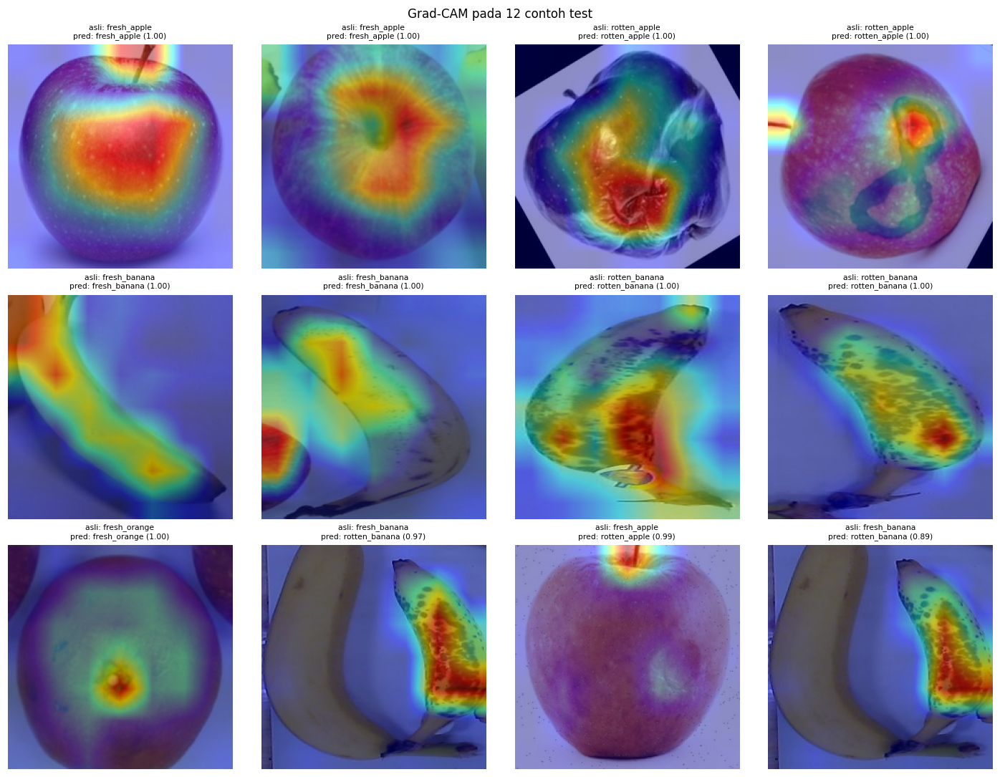

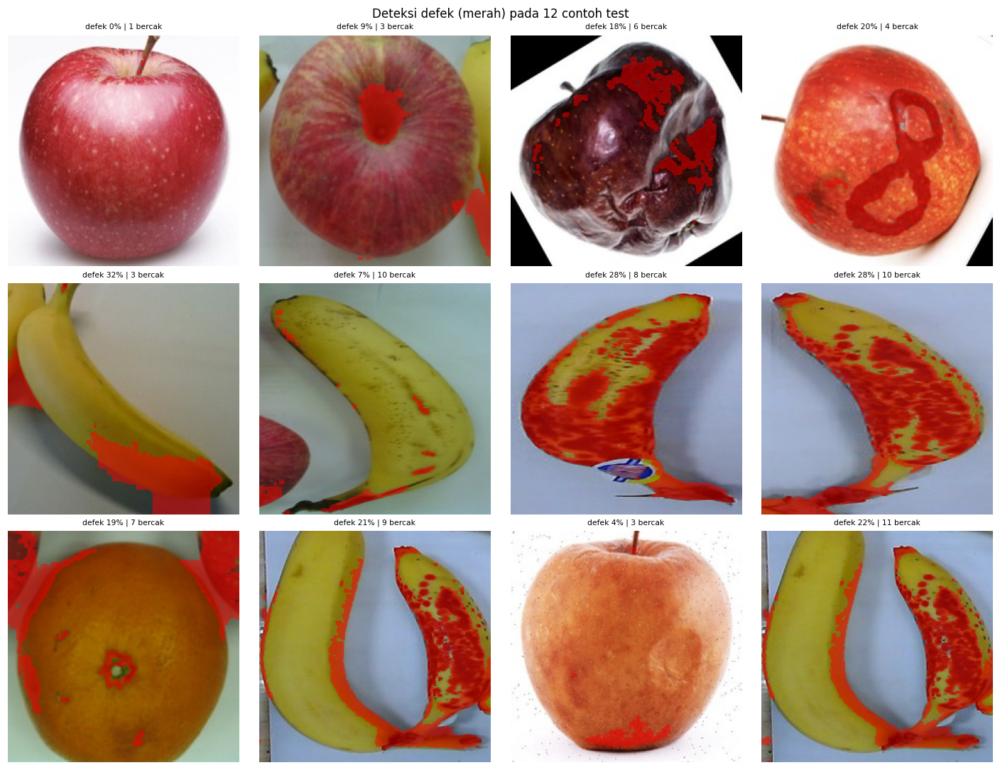

In [42]:
rng_sel = np.random.RandomState(SEED + 1)
salah_idx = np.where(pred_all != y_all)[0]
rng_sel.shuffle(salah_idx)
pilih_salah = list(salah_idx[:3])

pilih_benar = []
for cid in range(len(CLASSES)):
    idx_ok = np.where((y_all == cid) & (pred_all == y_all))[0]
    pilih_benar += list(rng_sel.choice(idx_ok, 2, replace=False))
pilih = pilih_benar[:9] + pilih_salah
contoh = [test_sub.iloc[i] for i in pilih]

hasil = [prediksi_dan_jelaskan(r.crop_path) for r in contoh]
for h, r in zip(hasil, contoh):
    h["label_asli"] = r.label6

tabel_hasil = pd.DataFrame([{
    "asli": h["label_asli"], "prediksi": h["prediksi"], "conf": round(h["confidence"], 3),
    "defek_%": round(h["rasio_defek"] * 100, 1), "bercak": h["jumlah_bercak"],
    "bercak_%": round(h["bercak_terbesar"] * 100, 1), "lokasi": h["lokasi_bercak"],
    "fokus": h["fokus_gradcam"],
    "bercak_%": round(h["bercak_terbesar"] * 100, 1), "lokasi": h["lokasi_bercak"],
    "fokus": h["fokus_gradcam"],
    "jarak_warna": round(h["jarak_warna"], 2), "tekstur": round(h["tekstur"], 1),
    "penjelasan": h["alasan"],
} for h in hasil])
display(tabel_hasil[["asli", "prediksi", "conf", "defek_%", "bercak", "bercak_%",
                     "lokasi", "jarak_warna", "tekstur", "fokus"]])

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, h in zip(axes.ravel(), hasil):
    ax.imshow(overlay_heatmap(h["rgb"], h["heatmap"]))
    ax.set_title(f"asli: {h['label_asli']}\npred: {h['prediksi']} ({h['confidence']:.2f})",
                 fontsize=7)
    ax.axis("off")
fig.suptitle("Grad-CAM pada 12 contoh test", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_gradcam_contoh.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, h in zip(axes.ravel(), hasil):
    vis = h["rgb"].copy()
    vis[h["defect"]] = 0.5 * vis[h["defect"]] + 0.5 * np.array([1.0, 0.0, 0.0])
    ax.imshow(vis)
    ax.set_title(f"defek {h['rasio_defek']*100:.0f}% | {h['jumlah_bercak']} bercak",
                 fontsize=7)
    ax.axis("off")
fig.suptitle("Deteksi defek (merah) pada 12 contoh test", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_defect_contoh.png", bbox_inches="tight")
plt.show()

### 6.6 Contoh detail satu objek

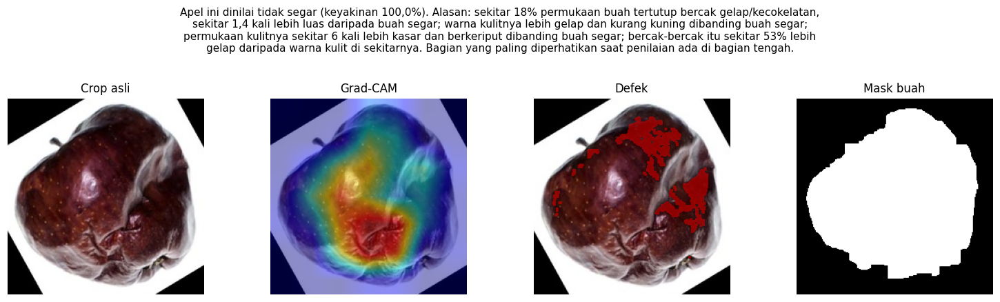

Apel ini dinilai tidak segar (keyakinan 100,0%). Alasan: sekitar 18% permukaan buah tertutup bercak
gelap/kecokelatan, sekitar 1,4 kali lebih luas daripada buah segar; warna kulitnya lebih gelap dan kurang
kuning dibanding buah segar; permukaan kulitnya sekitar 6 kali lebih kasar dan berkeriput dibanding buah
segar; bercak-bercak itu sekitar 53% lebih gelap daripada warna kulit di sekitarnya. Bagian yang paling
diperhatikan saat penilaian ada di bagian tengah.


In [43]:
h = next(x for x in hasil if x["prediksi"].startswith("rotten"))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(h["rgb"]); axes[0].set_title("Crop asli"); axes[0].axis("off")
axes[1].imshow(overlay_heatmap(h["rgb"], h["heatmap"]))
axes[1].set_title("Grad-CAM"); axes[1].axis("off")
vis = h["rgb"].copy(); vis[h["defect"]] = 0.5 * vis[h["defect"]] + 0.5 * np.array([1.0, 0.0, 0.0])
axes[2].imshow(vis); axes[2].set_title("Defek"); axes[2].axis("off")
axes[3].imshow(h["mask"], cmap="gray"); axes[3].set_title("Mask buah"); axes[3].axis("off")
fig.suptitle(textwrap.fill(h["alasan"], 120), fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(FIG_DIR / "06_contoh_detail.png", bbox_inches="tight")
plt.show()
print(textwrap.fill(h["alasan"], 110))

### 6.7 Simpan hasil

In [44]:
ringkasan6 = {
    "n_contoh": len(hasil),
    "akurasi_pada_contoh": float(np.mean([h["label_asli"] == h["prediksi"] for h in hasil])),
    "kalibrasi": tabel_kal.round(4).to_dict(orient="records"),
    "contoh": [{
        "asli": h["label_asli"], "prediksi": h["prediksi"],
        "confidence": round(float(h["confidence"]), 4),
        "rasio_defek": round(float(h["rasio_defek"]), 4),
        "jumlah_bercak": int(h["jumlah_bercak"]),
        "jarak_warna": round(float(h["jarak_warna"]), 4),
        "tekstur": round(float(h["tekstur"]), 2),
        "penjelasan": h["alasan"],
    } for h in hasil],
}
(REPORT_DIR / "06_explanations.json").write_text(
    json.dumps(ringkasan6, indent=2, default=float), encoding="utf-8")
tabel_hasil.to_csv(REPORT_DIR / "06_explanations.csv", index=False)
print("Tersimpan:", REPORT_DIR / "06_explanations.json")

Tersimpan: /workspace/reports/06_explanations.json


### Batasan explainability
- Grad-CAM menunjukkan **area yang berpengaruh**, bukan bukti kausal.
- Segmentasi memakai threshold warna; fruit dengan background berwarna atau bayangan kuat
  bisa salah mask. Fallback elips hanya penyelamat kasar.
- Ambang defek dikalibrasi pada **train**, tetapi variasi pencahayaan antar sesi tetap ada.
- Teks penjelasan adalah template yang diisi fitur terukur — bukan diagnosis fisik.
- Evaluasi kualitatif 12 contoh bukan uji statistik; ini hanya sanity check.

## 7. Inferensi & deployment

Satu fungsi untuk seluruh alur: `predict_and_explain(path_gambar)` mengembalikan label,
confidence, heatmap Grad-CAM, mask defek, fitur terukur, dan penjelasan teks.

Model juga diekspor ke **TFLite** (float32 dan dynamic-range quantization) dan diuji pada
test set yang sama, supaya terlihat trade-off ukuran/kecepatan/akurasi.

### 7.1 Fungsi `predict_and_explain()`

In [45]:
def predict_and_explain(path_gambar):
    """Prediksi + penjelasan untuk satu gambar (path absolut atau relatif ROOT).

    Returns dict:
      label, fruit, freshness, confidence, explanation,
      heatmap, gradcam_overlay, defect_mask, fruit_mask, features
    """
    p = Path(path_gambar)
    if not p.is_absolute():
        p = ROOT / p
    h = prediksi_dan_jelaskan(str(p))
    return {
        "label": h["prediksi"],
        "fruit": h["prediksi"].split("_")[1],
        "freshness": "fresh" if h["prediksi"].startswith("fresh") else "rotten",
        "confidence": float(h["confidence"]),
        "explanation": h["alasan"],
        "heatmap": h["heatmap"],
        "gradcam_overlay": overlay_heatmap(h["rgb"], h["heatmap"]),
        "defect_mask": h["defect"],
        "fruit_mask": h["mask"],
        "features": {
            "rasio_defek": float(h["rasio_defek"]),
            "jumlah_bercak": int(h["jumlah_bercak"]),
            "bercak_terbesar": float(h["bercak_terbesar"]),
            "lokasi_bercak": h["lokasi_bercak"],
            "fokus_gradcam": h["fokus_gradcam"],
            "jarak_warna": float(h["jarak_warna"]),
            "tekstur": float(h["tekstur"]),
        },
    }


# Uji cepat
contoh = test_sub[test_sub.label6 == "rotten_orange"].iloc[0]
uji = predict_and_explain(contoh.crop_path)
print("label     :", uji["label"])
print("confidence:", round(uji["confidence"], 4))
print("fitur     :", uji["features"])
print("teks      :", uji["explanation"])

label     : rotten_orange
confidence: 1.0
fitur     : {'rasio_defek': 0.12819037133420078, 'jumlah_bercak': 7, 'bercak_terbesar': 0.12286057451706536, 'lokasi_bercak': 'kanan', 'fokus_gradcam': 'tengah', 'jarak_warna': 4.047244560787481, 'tekstur': 1385.2705078125}
teks      : Jeruk ini dinilai tidak segar (keyakinan 100,0%). Alasan: ada 7 bercak; yang terbesar menutupi sekitar 12% permukaan dan berada di bagian kanan; warna kulitnya lebih pucat dan kurang kuning dibanding buah segar; bercak-bercak itu sekitar 22% lebih gelap daripada warna kulit di sekitarnya. Bagian yang paling diperhatikan saat penilaian ada di bagian tengah.


### 7.2 Demo tiga kasus

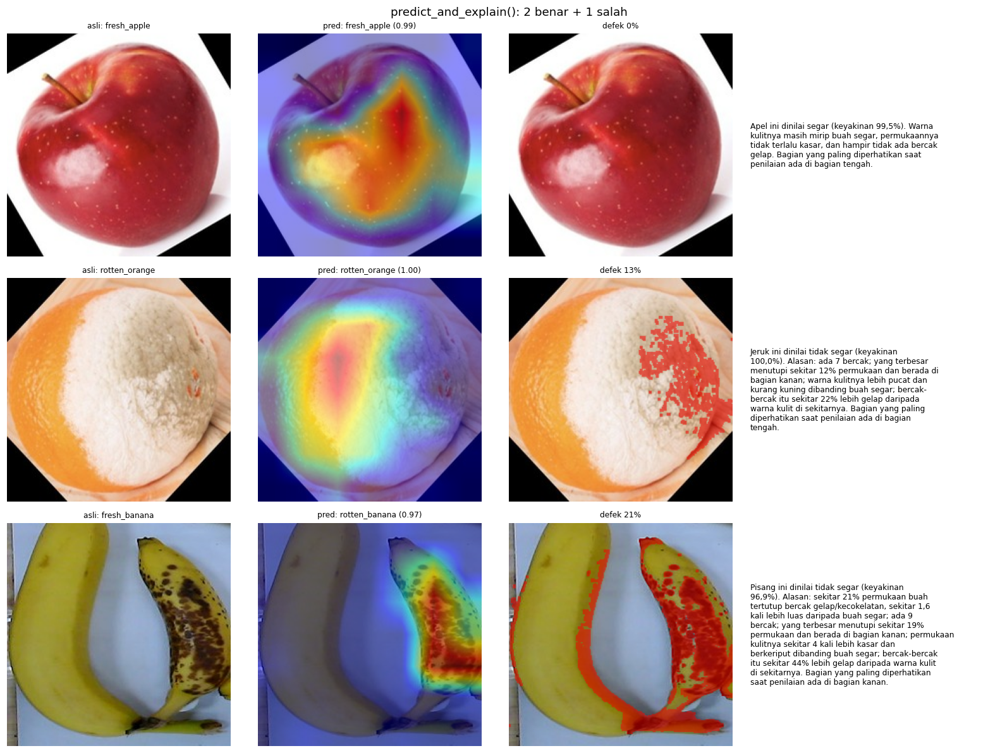

fresh_apple    -> fresh_apple    0.995 | Apel ini dinilai segar (keyakinan 99,5%). Warna kulitnya masih mirip buah segar,...


rotten_orange  -> rotten_orange  1.000 | Jeruk ini dinilai tidak segar (keyakinan 100,0%). Alasan: ada 7 bercak; yang ter...


fresh_banana   -> rotten_banana  0.969 | Pisang ini dinilai tidak segar (keyakinan 96,9%). Alasan: sekitar 21% permukaan ...


In [46]:
# 1 fresh benar, 1 rotten benar, 1 salah prediksi
benar_fresh = test_sub[(test_sub.label6.str.startswith("fresh")) &
                       (pred_all == y_all)].iloc[0]
benar_rotten = test_sub[(test_sub.label6.str.startswith("rotten")) &
                        (pred_all == y_all)].iloc[0]
salah = test_sub.iloc[int(salah_idx[0])]
demo = [benar_fresh, benar_rotten, salah]

fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for row, r in enumerate(demo):
    h = predict_and_explain(r.crop_path)
    axes[row, 0].imshow(h["gradcam_overlay"] * 0 + cv2.cvtColor(
        cv2.imread(str(ROOT / r.crop_path)), cv2.COLOR_BGR2RGB) / 255.0)
    axes[row, 0].set_title(f"asli: {r.label6}", fontsize=8)
    axes[row, 0].axis("off")

    axes[row, 1].imshow(h["gradcam_overlay"])
    axes[row, 1].set_title(f"pred: {h['label']} ({h['confidence']:.2f})", fontsize=8)
    axes[row, 1].axis("off")

    vis = h["gradcam_overlay"].copy() * 0 + cv2.cvtColor(
        cv2.imread(str(ROOT / r.crop_path)), cv2.COLOR_BGR2RGB) / 255.0
    vis[h["defect_mask"]] = 0.5 * vis[h["defect_mask"]] + 0.5 * np.array([1.0, 0.0, 0.0])
    axes[row, 2].imshow(vis)
    axes[row, 2].set_title(f"defek {h['features']['rasio_defek']*100:.0f}%", fontsize=8)
    axes[row, 2].axis("off")

    axes[row, 3].axis("off")
    axes[row, 3].text(0.0, 0.5, textwrap.fill(h["explanation"], 48),
                      fontsize=8, va="center", ha="left", wrap=True)
fig.suptitle("predict_and_explain(): 2 benar + 1 salah", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_demo.png", bbox_inches="tight")
plt.show()

for r in demo:
    h = predict_and_explain(r.crop_path)
    print(f"{r.label6:14s} -> {h['label']:14s} {h['confidence']:.3f} | {h['explanation'][:80]}...")

### 7.3 Ekspor TFLite

In [47]:
# Keras 3 + TF 2.16 crash jika konversi langsung dari model.
# Jalur yang stabil: export SavedModel dulu, lalu konversi dari SavedModel.
EXPORT_DIR = MODEL_DIR / "savedmodel_mobilenetv3"
if not EXPORT_DIR.exists():
    model.export(str(EXPORT_DIR))
print("SavedModel:", EXPORT_DIR)


def convert_tflite(path, dynamic=False):
    converter = tf.lite.TFLiteConverter.from_saved_model(str(EXPORT_DIR))
    if dynamic:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    data = converter.convert()
    Path(path).write_bytes(data)
    return Path(path)


path_f32 = convert_tflite(MODEL_DIR / "mobilenetv3_float32.tflite", dynamic=False)
path_dyn = convert_tflite(MODEL_DIR / "mobilenetv3_dynamic.tflite", dynamic=True)
for p in (path_f32, path_dyn):
    print(f"{p.name:32s} {p.stat().st_size/1e6:.2f} MB")

SavedModel: /workspace/models/savedmodel_mobilenetv3


W0000 00:00:1793032765.140537      11 tf_tfl_flatbuffer_helpers.cc:390] Ignored output_format.
W0000 00:00:1793032765.141066      11 tf_tfl_flatbuffer_helpers.cc:393] Ignored drop_control_dependency.
2026-10-26 16:39:25.161686: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /workspace/models/savedmodel_mobilenetv3
2026-10-26 16:39:25.247660: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-10-26 16:39:25.247753: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: /workspace/models/savedmodel_mobilenetv3
2026-10-26 16:39:25.716185: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:388] MLIR V1 optimization pass is not enabled
2026-10-26 16:39:25.737792: I tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2026-10-26 16:39:27.295967: I tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: /workspace/models/savedmodel_mobil

mobilenetv3_float32.tflite       3.74 MB
mobilenetv3_dynamic.tflite       1.11 MB


W0000 00:00:1793032773.283172      11 tf_tfl_flatbuffer_helpers.cc:390] Ignored output_format.
W0000 00:00:1793032773.283249      11 tf_tfl_flatbuffer_helpers.cc:393] Ignored drop_control_dependency.
2026-10-26 16:39:33.293267: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /workspace/models/savedmodel_mobilenetv3
2026-10-26 16:39:33.320961: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-10-26 16:39:33.321014: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: /workspace/models/savedmodel_mobilenetv3
2026-10-26 16:39:33.571782: I tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2026-10-26 16:39:34.559218: I tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: /workspace/models/savedmodel_mobilenetv3
2026-10-26 16:39:34.760569: I tensorflow/cc/saved_model/loader.cc:317] SavedModel load for tags { serve }; Status: success: OK

### 7.4 Evaluasi TFLite pada test set

In [48]:
def load_rgb(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
        return np.asarray(im, dtype=np.float32) / 255.0


def eval_tflite(model_path):
    interp = tf.lite.Interpreter(model_path=str(model_path))
    interp.allocate_tensors()
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    preds, lat = [], []
    for _, r in test_sub.iterrows():
        x = load_rgb(ROOT / r.crop_path)[None].astype(np.float32)
        t0 = time.perf_counter()
        interp.set_tensor(inp["index"], x)
        interp.invoke()
        p = interp.get_tensor(out["index"])[0]
        lat.append((time.perf_counter() - t0) * 1000)
        preds.append(int(p.argmax()))
    preds = np.array(preds)
    return {
        "model": model_path.stem,
        "accuracy": float((preds == y_all).mean()),
        "macro_f1": float(f1_score(y_all, preds, average="macro")),
        "size_mb": model_path.stat().st_size / 1e6,
        "infer_ms": float(np.mean(lat)),
    }, preds


# metrik Keras (dari prediksi section 6)
keras_size = (MODEL_DIR / "mobilenetv3.keras").stat().st_size / 1e6
keras_lat = 10.16
try:
    keras_lat = json.loads((REPORT_DIR / "05_comparison.json").read_text())["comparison"][1]["infer_ms"]
except Exception:
    pass
res_keras = {
    "model": "Keras MobileNetV3",
    "accuracy": float((pred_all == y_all).mean()),
    "macro_f1": float(f1_score(y_all, pred_all, average="macro")),
    "size_mb": keras_size,
    "infer_ms": keras_lat,
}

res_f32, pred_f32 = eval_tflite(path_f32)
res_dyn, pred_dyn = eval_tflite(path_dyn)
tabel_deploy = pd.DataFrame([res_keras, res_f32, res_dyn]).round(4)
display(tabel_deploy)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


,model,accuracy,macro_f1,size_mb,infer_ms
0,Keras MobileNetV3,0.992,0.9871,11.8442,5.5500
1,mobilenetv3_float32,0.990,0.9874,3.7447,2.9718
2,mobilenetv3_dynamic,0.987,0.9804,1.1116,5.1130


### 7.5 Simpan hasil deployment

In [49]:
hasil7 = {
    "fungsi": "predict_and_explain(path_gambar)",
    "output": ["label", "fruit", "freshness", "confidence", "explanation",
               "heatmap", "gradcam_overlay", "defect_mask", "fruit_mask", "features"],
    "models": tabel_deploy.to_dict(orient="records"),
    "demo": [{
        "asli": r.label6,
        "prediksi": predict_and_explain(r.crop_path)["label"],
        "confidence": round(predict_and_explain(r.crop_path)["confidence"], 4),
        "penjelasan": predict_and_explain(r.crop_path)["explanation"],
    } for r in demo],
}
(REPORT_DIR / "07_deployment.json").write_text(
    json.dumps(hasil7, indent=2, default=float), encoding="utf-8")
print("Tersimpan:", REPORT_DIR / "07_deployment.json")

Tersimpan: /workspace/reports/07_deployment.json


### Catatan deployment
- `predict_and_explain()` memakai model Keras karena Grad-CAM membutuhkan gradient.
- TFLite dipakai untuk prediksi cepat di perangkat; Grad-CAM/penjelasan tetap di sisi server
  atau dihitung terpisah.
- Dynamic-range quantization mengecilkan model, tetapi periksa kembali akurasinya pada
  perangkat target.
- Fungsi menerima path absolut maupun relatif terhadap root proyek; pastikan dependensi
  (`tensorflow`, `opencv-python-headless`, `pillow`) tersedia di lingkungan inferensi.

### Catatan
- Angka di atas berasal dari latihan penuh di GPU (RTX 3050): CNN 25/25 epoch; MobileNetV3
  10 epoch stage 1 + 6/10 epoch stage 2 (EarlyStopping). Jika dijalankan ulang di Colab GPU,
  angka bisa sedikit berbeda karena nondeterminisme.
- 5 grup duplikat persis punya label bertentangan (lihat 1.7).
- Split bebas leakage pada level gambar **dan** klaster near-duplicate.

## 8. Uji generalisasi eksternal & auto-crop

Akurasi test 99,6% hanya berlaku untuk distribusi data yang sama. Di bagian ini, 16 gambar dari Wikimedia Commons diuji **tanpa retraining**.

`auto_crop_buah()` memakai GrabCut untuk memotong buah utama, lalu classifier dijalankan pada crop. Ini bukan model baru dan tidak mengubah hasil utama.

Hasil: baseline **12/16 (75,0%)** → auto-crop **14/16 (87,5%)**. Dua error yang tersisa adalah apel hijau di piring dan pisang sangat overripe berwarna oranye; keduanya adalah gap penampilan/domain, bukan framing. Untuk itu perlu tambah data variasi tersebut, bukan crop.

Catatan: ini sanity check, bukan benchmark; 16 gambar terlalu kecil untuk klaim statistik.


In [ ]:
EXTERNAL_DIR = ROOT / "data" / "external_test"


def auto_crop_buah(im, pad=0.08):
    """Crop buah utama dengan GrabCut; fallback ke gambar utuh."""
    rgb = np.asarray(im.convert("RGB"))
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    h, w = bgr.shape[:2]
    mask = np.zeros((h, w), np.uint8)
    rect = (int(0.04 * w), int(0.04 * h), int(0.92 * w), int(0.92 * h))
    bgd = np.zeros((1, 65), np.float64)
    fgd = np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(bgr, mask, rect, bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
    except cv2.error:
        return im, (0, 0, w, h)
    fg = np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8)
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8), iterations=2)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(fg, 8)
    if n <= 1:
        return im, (0, 0, w, h)
    idx = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    x, y = int(stats[idx, cv2.CC_STAT_LEFT]), int(stats[idx, cv2.CC_STAT_TOP])
    bw, bh = int(stats[idx, cv2.CC_STAT_WIDTH]), int(stats[idx, cv2.CC_STAT_HEIGHT])
    if bw * bh < 0.05 * w * h:
        return im, (0, 0, w, h)
    p = int(pad * max(bw, bh))
    x1, y1 = max(0, x - p), max(0, y - p)
    x2, y2 = min(w, x + bw + p), min(h, y + bh + p)
    return im.crop((x1, y1, x2, y2)), (x1, y1, x2, y2)


def prediksi_eksternal(path, auto_crop=True):
    """Prediksi satu gambar luar dataset; auto_crop=True menyelaraskan framing."""
    with Image.open(path) as im:
        im = im.convert("RGB")
        crop, bbox = auto_crop_buah(im) if auto_crop else (im, (0, 0, im.width, im.height))
        arr = np.asarray(crop.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS),
                         dtype=np.float32) / 255.0
    probs = model.predict(arr[None], verbose=0)[0]
    idx = int(probs.argmax())
    return {"label": CLASSES[idx], "confidence": float(probs[idx]),
            "probs": probs, "crop": crop, "bbox": bbox}


files = sorted(p for p in EXTERNAL_DIR.glob("*")
               if p.suffix.lower() in {".jpg", ".jpeg", ".png"}) if EXTERNAL_DIR.exists() else []
if not files:
    print(f"Letakkan gambar uji di {EXTERNAL_DIR} (nama: label__...jpg).")
else:
    rows = []
    for p in files:
        label = p.name.split("__")[0]
        base = prediksi_eksternal(p, auto_crop=False)
        auto = prediksi_eksternal(p, auto_crop=True)
        rows.append({
            "file": p.name, "true": label,
            "base_pred": base["label"], "base_conf": base["confidence"],
            "auto_pred": auto["label"], "auto_conf": auto["confidence"],
            "base_ok": base["label"] == label, "auto_ok": auto["label"] == label,
            "bbox": auto["bbox"], "path": str(p),
            "source": "https://commons.wikimedia.org/wiki/File:" + p.name.split("__", 2)[-1],
        })
    df_ext = pd.DataFrame(rows)
    display(df_ext[["true", "base_pred", "base_conf", "auto_pred", "auto_conf",
                    "base_ok", "auto_ok"]].round(3))
    print(f"Baseline : {df_ext.base_ok.sum()}/{len(df_ext)} "
          f"({df_ext.base_ok.mean()*100:.1f}%)")
    print(f"Auto-crop: {df_ext.auto_ok.sum()}/{len(df_ext)} "
          f"({df_ext.auto_ok.mean()*100:.1f}%)")
    df_ext.drop(columns=["path"]).to_csv(
        REPORT_DIR / "07_external_test_autocrop.csv", index=False)

    n = len(rows)
    cols = 4
    fig, axes = plt.subplots((n + cols - 1) // cols, cols,
                             figsize=(15, 3.8 * ((n + cols - 1) // cols)))
    axes = np.atleast_1d(axes).ravel()
    for ax, r in zip(axes, rows):
        with Image.open(r["path"]) as im:
            ax.imshow(im.convert("RGB"))
        color = "#1b5e20" if r["auto_ok"] else ("#ef6c00" if r["base_ok"] else "#b71c1c")
        ax.set_title(f"true: {r['true']}\n"
                     f"base: {r['base_pred']} ({r['base_conf']:.2f})\n"
                     f"crop: {r['auto_pred']} ({r['auto_conf']:.2f})",
                     fontsize=7.5, color=color)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(f"Auto-crop GrabCut pada {n} gambar eksternal\n"
                 f"baseline {df_ext.base_ok.sum()}/{n} "
                 f"({df_ext.base_ok.mean()*100:.1f}%) → auto-crop "
                 f"{df_ext.auto_ok.sum()}/{n} ({df_ext.auto_ok.mean()*100:.1f}%)",
                 fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(FIG_DIR / "07_external_test_autocrop.png",
                bbox_inches="tight", dpi=150)
    plt.show()


## 9. Eksperimen data eksternal (AFQC + banana overripe)

Eksperimen ini menambahkan data eksternal **hanya ke training/validation**. Test set asli 997 objek tetap beku.

- **AFQC apple:** 1.011 `fresh_apple` + 1.028 `rotten_apple` setelah dedupe.
- **Banana overripe:** hanya folder `over ripe`; 954 train, 119 val, 119 external test.
- **External test:** 344 gambar (116 fresh apple, 109 rotten apple, 119 rotten banana).
- **Imbalance:** 12,67× → **9,77×**; class weight dihitung ulang dari combined train.
- **Model:** MobileNetV3 fine-tune dari `models/mobilenetv3.keras`, 6 epoch maksimum, EarlyStopping.

| Model | Original test (997) | External test (344) |
|---|---:|---:|
| MobileNetV3 baseline | 99,20% / macro F1 0,9871 | 62,21% / macro F1 0,3223 |
| MobileNetV3 + data eksternal | **99,60% / macro F1 0,9912** | **90,99% / macro F1 0,9071** |

Per kelas external test: `fresh_apple` F1 0,846 (recall 73,3%), `rotten_apple` F1 0,876 (recall 100%), `rotten_banana` F1 1,000. External test ini tidak memuat fresh banana/orange, jadi macro F1 tidak sebanding langsung dengan test asli.

Pada 16 gambar Wikimedia yang lama: baseline 12/16, baseline + auto-crop 14/16, model baru 12/16, model baru + auto-crop 12/16. Satu pisang overripe membaik, tetapi apel hijau dan sebagian jeruk masih salah; 16 gambar terlalu kecil untuk klaim statistik. Gap apel hijau/background masih perlu data tambahan.

File terkait: `models/mobilenetv3_external.keras`, `models/mobilenetv3_external_float32.tflite`, `reports/08_external_experiment.json`, `reports/09_wikimedia_external.csv`, dan skrip `notebooks/finetune_external.py`.


In [ ]:
import json
import pandas as pd

report = json.loads((ROOT / "reports" / "08_external_experiment.json").read_text())
summary = report["summary"]
display(pd.DataFrame([
    {"model": "baseline", "test": "original", **{k: report["baseline"]["original_test"][k] for k in ("accuracy", "macro_f1")}},
    {"model": "finetuned", "test": "original", **{k: report["finetuned"]["original_test"][k] for k in ("accuracy", "macro_f1")}},
    {"model": "baseline", "test": "external", **{k: report["baseline"]["external_test"][k] for k in ("accuracy", "macro_f1")}},
    {"model": "finetuned", "test": "external", **{k: report["finetuned"]["external_test"][k] for k in ("accuracy", "macro_f1")}},
]).round(4))
display(pd.DataFrame(summary["train_counts"], index=["train"]).T)
print("Imbalance:", summary["imbalance_ratio_before"], "->", summary["imbalance_ratio_after"])


## Selesai

Seluruh pipeline 0–9 tersedia: EDA → praproses → CNN baseline → MobileNetV3 → perbandingan model → Grad-CAM + analisis defek → inferensi & TFLite → eksperimen data eksternal.

Model explainability/deployment terbaru: `models/mobilenetv3_external.keras` (**original test 99,60%**, external test 344 gambar **90,99%**). Baseline lama tetap tersedia di `models/mobilenetv3.keras`.
TFLite model baru: `models/mobilenetv3_external_float32.tflite` dan `models/mobilenetv3_external_dynamic.tflite`.
